# Klasifikasi Tumor Otak BRISC2025 menggunakan EdgeNeXt

Notebook ini dibuat untuk Visual Studio Code dengan Python 3.10.

Penelitian hanya menggunakan satu arsitektur, yaitu EdgeNeXt. Perbandingan dilakukan antara EdgeNeXt baseline dan EdgeNeXt setelah tuning.

Catatan penting:
- Dataset BRISC2025 pada laptop ini sudah berupa JPG 2D.
- Folder test resmi tidak digunakan untuk train atau validation.
- Karena patient_id tidak tersedia dengan jelas, evaluasi dilakukan pada tingkat gambar.
- Notebook tidak membuat data palsu dan tidak menyatakan hasil sebelum cell dijalankan.

In [1]:
# Cell 1 - Import library dan pemeriksaan environment
import gc
import hashlib
import json
import os
import platform
import random
import re
import sys
import time
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import psutil
import seaborn as sns
import sklearn
import torch
import torch.nn as nn
import torchvision
from PIL import Image, ImageFile, ImageOps
from IPython.display import display
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    precision_recall_fscore_support,
    roc_auc_score,
)
from sklearn.model_selection import train_test_split
from torch.utils.data import DataLoader, Dataset
from torchvision import transforms
from torchvision.transforms import functional as TF

ImageFile.LOAD_TRUNCATED_IMAGES = False
warnings.filterwarnings("ignore")

try:
    import timm
except ImportError:
    timm = None

print("Python       :", sys.version)
print("Python path  :", sys.executable)
print("PyTorch      :", torch.__version__)
print("Torchvision  :", torchvision.__version__)
print("Scikit-learn:", sklearn.__version__)
print("timm        :", getattr(timm, "__version__", "BELUM TERPASANG"))
print("CUDA build   :", getattr(getattr(torch, "version", None), "cuda", None))
print("CUDA tersedia:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU          :", torch.cuda.get_device_name(0))
    print("GPU memory awal (MB):", round(torch.cuda.memory_allocated() / 1024**2, 2))
else:
    print("GPU          : tidak aktif; training akan menggunakan CPU.")
    print("Catatan      : laptop memiliki GPU NVIDIA, tetapi PyTorch saat ini adalah build CPU.")


Python       : 3.10.3 (tags/v3.10.3:a342a49, Mar 16 2022, 13:07:40) [MSC v.1929 64 bit (AMD64)]
Python path  : c:\Users\alfan\AppData\Local\Programs\Python\Python310\python.exe
PyTorch      : 2.7.1+cu118
Torchvision  : 0.22.1+cu118
Scikit-learn: 1.7.2
timm        : 1.0.30
CUDA build   : 11.8
CUDA tersedia: True
GPU          : NVIDIA GeForce GTX 1650
GPU memory awal (MB): 0.0


## 2. Konfigurasi penelitian

Cell ini menjadi satu-satunya tempat utama untuk mengubah pengaturan eksperimen.

Lokasi dataset diperiksa pada dua kemungkinan. Lokasi yang benar di laptop saat ini adalah folder dataset yang berada sejajar dengan folder Code Program, bukan di dalam Code Program.

In [2]:
# Cell 2 - Konfigurasi penelitian
PROJECT_ROOT = Path(r"E:\CNN(Tumor otak)\Code Program")
EXTERNAL_MENDELEY_ROOT = PROJECT_ROOT / "external_datasets" / "mendeley_82mtzd8x72_v1"
EXTERNAL_MENDELEY_RAW = EXTERNAL_MENDELEY_ROOT / "raw"
EXTERNAL_AUDIT_SCRIPT = PROJECT_ROOT / "scripts" / "prepare_mendeley_external.py"

DATA_DIR_CANDIDATES = [
    PROJECT_ROOT.parent / "brisc2025-v6" / "brisc2025" / "classification_task",
    PROJECT_ROOT / "brisc2025-v6" / "brisc2025" / "classification_task",
]
DATA_DIR = next((path for path in DATA_DIR_CANDIDATES if path.exists()), None)

if DATA_DIR is None:
    checked = "\n".join(str(path) for path in DATA_DIR_CANDIDATES)
    raise FileNotFoundError(
        "Folder dataset tidak ditemukan. Lokasi yang diperiksa:\n" + checked +
        "\nPastikan folder bernama classification_task, bukan classification\\_task."
    )

OUTPUT_ROOT = PROJECT_ROOT / "hasil_edgenext"
RUN_ID = time.strftime("%Y%m%d_%H%M%S")
RUN_ROOT = OUTPUT_ROOT / RUN_ID
BASELINE_DIR = RUN_ROOT / "01_baseline"
TUNING_DIR = RUN_ROOT / "02_tuning"
FINAL_DIR = RUN_ROOT / "03_final"
COMPARISON_DIR = RUN_ROOT / "04_comparison"

for folder in [RUN_ROOT, BASELINE_DIR, TUNING_DIR, FINAL_DIR, COMPARISON_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

CLASS_NAMES = ["glioma", "meningioma", "no_tumor", "pituitary"]
NUM_CLASSES = len(CLASS_NAMES)
IMAGE_SIZE = 224
BATCH_SIZE = 16
NUM_WORKERS = 0

# Hyperparameter training
LEARNING_RATE = 1e-4 # reduced to avoid overfitting from 5e-4
WEIGHT_DECAY = 1e-4
VAL_SIZE = 0.20
RANDOM_SEED = 42
MODEL_NAME = "edgenext_xx_small"
USE_PRETRAINED = True
# Training dibatasi maksimal 30 epoch dan dapat berhenti lebih awal
# jika validation macro F1 tidak membaik selama 5 epoch.
BASELINE_EPOCHS = 40 # reduced to 40 from 50
TUNING_EPOCHS = 50
FINAL_EPOCHS = 80
EARLY_STOPPING_PATIENCE = 8 # reduced to 8 from 10
MAX_TUNING_TRIALS = 3

# Perbaikan dari analisis kesalahan (results/error_feature_analysis/TEMUAN.md)
# Augmentasi: rotasi kecil (citra miring) dan intensitas lebih lebar (beda protokol MRI)
AUG_ROTATION_DEGREES = 10          # 0 = matikan rotasi
AUG_TRANSLATE = 0.05
AUG_SCALE = (0.90, 1.10)
AUG_STRONG_INTENSITY = True        # False = augmentasi intensitas lama
# Inferensi
USE_TTA = True                     # rata-rata prediksi gambar asli + flip horizontal
REVIEW_FLAG_RATE = 0.02            # tandai 2% prediksi paling tidak yakin (ambang dari VALIDATION)
REVIEW_THRESHOLD_FALLBACK = 0.90   # dipakai jika validation loader tidak diberikan

# Penyeimbangan kelas dengan SMOTE (hanya data TRAIN; validation dan test tidak diubah)
USE_SMOTE = True                   # False = tanpa SMOTE (data asli saja)
SMOTE_K_NEIGHBORS = 5
SMOTE_SAME_PLANE = True            # tetangga hanya dari bidang irisan yang sama (ax/co/sa)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
PIN_MEMORY = DEVICE.type == "cuda"

print("PROJECT_ROOT:", PROJECT_ROOT)
print("DATA_DIR    :", DATA_DIR)
print("OUTPUT_ROOT :", OUTPUT_ROOT)
print("RUN_ROOT    :", RUN_ROOT)
print("DEVICE      :", DEVICE)


PROJECT_ROOT: E:\CNN(Tumor otak)\Code Program
DATA_DIR    : E:\CNN(Tumor otak)\Code Program\brisc2025-v6\brisc2025\classification_task
OUTPUT_ROOT : E:\CNN(Tumor otak)\Code Program\hasil_edgenext
RUN_ROOT    : E:\CNN(Tumor otak)\Code Program\hasil_edgenext\20261119_011920
DEVICE      : cuda


In [3]:
# Cell 3 - Fungsi bantuan
IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff"}

def crop_brain_pad_square(image):
    gray = np.asarray(ImageOps.grayscale(image), dtype=np.float32)
    low, high = np.percentile(gray, [5, 99])
    threshold = max(3.0, low + 0.12 * (high - low))
    foreground = gray > threshold
    rows = np.flatnonzero(foreground.any(axis=1))
    cols = np.flatnonzero(foreground.any(axis=0))
    if len(rows) and len(cols):
        image = image.crop((cols[0], rows[0], cols[-1] + 1, rows[-1] + 1))
    side = max(image.size)
    left = (side - image.width) // 2
    top = (side - image.height) // 2
    return ImageOps.expand(
        image,
        border=(left, top, side - image.width - left, side - image.height - top),
        fill=0,
    ).convert("RGB")

def preprocess_brain_image(image, image_size=224):
    image = crop_brain_pad_square(image).resize((image_size, image_size), Image.Resampling.LANCZOS)
    array = np.asarray(ImageOps.grayscale(image), dtype=np.float32)
    low, high = np.percentile(array, [1, 99])
    if high <= low:
        normalized = np.zeros_like(array, dtype=np.uint8)
    else:
        normalized = np.clip((array - low) / (high - low) * 255.0, 0, 255).astype(np.uint8)
    return Image.fromarray(normalized, mode="L").convert("RGB")

class RandomGamma:
    def __init__(self, probability=0.35, gamma_range=(0.85, 1.15)):
        self.probability = probability
        self.gamma_range = gamma_range

    def __call__(self, image):
        if random.random() >= self.probability:
            return image
        gamma = random.uniform(*self.gamma_range)
        return TF.adjust_gamma(image, gamma)

class AddGaussianNoise:
    def __init__(self, probability=0.20, standard_deviation=0.015):
        self.probability = probability
        self.standard_deviation = standard_deviation

    def __call__(self, tensor):
        if random.random() >= self.probability:
            return tensor
        noise = torch.randn_like(tensor) * self.standard_deviation
        return torch.clamp(tensor + noise, 0.0, 1.0)

def seed_everything(seed=RANDOM_SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

def gpu_memory_mb():
    if torch.cuda.is_available():
        return round(torch.cuda.max_memory_allocated() / 1024**2, 2)
    return 0.0

def process_ram_mb():
    return round(psutil.Process(os.getpid()).memory_info().rss / 1024**2, 2)

def save_json(data, path):
    def convert(value):
        if isinstance(value, Path):
            return str(value)
        if isinstance(value, torch.device):
            return str(value)
        if isinstance(value, torch.dtype):
            return str(value)
        if isinstance(value, np.ndarray):
            return value.tolist()
        if isinstance(value, (np.integer,)):
            return int(value)
        if isinstance(value, (np.floating,)):
            return float(value)
        if isinstance(value, (np.bool_,)):
            return bool(value)
        if isinstance(value, dict):
            return {str(k): convert(v) for k, v in value.items()}
        if isinstance(value, (list, tuple)):
            return [convert(v) for v in value]
        try:
            json.dumps(value)
            return value
        except TypeError:
            return str(value)
    Path(path).write_text(json.dumps(convert(data), indent=2), encoding="utf-8")

seed_everything()


## 3. Pemeriksaan dataset

Notebook membaca file nyata dari folder train dan test. Nama bidang axial, coronal, atau sagittal hanya dicatat jika informasinya terdapat pada nama file.

In [4]:
# Cell 4 - Membaca manifest train dan test
def detect_plane(filename):
    name = filename.lower()
    tokens = set(re.split(r"[_\-.]+", name))
    if "axial" in name or "ax" in tokens:
        return "axial"
    if "coronal" in name or "co" in tokens:
        return "coronal"
    if "sagittal" in name or "sa" in tokens:
        return "sagittal"
    return "unknown"

def file_sha256(image_path, chunk_size=1024 * 1024):
    digest = hashlib.sha256()
    with open(image_path, "rb") as file:
        for chunk in iter(lambda: file.read(chunk_size), b""):
            digest.update(chunk)
    return digest.hexdigest()

def scan_split(split_name):
    split_dir = DATA_DIR / split_name
    if not split_dir.exists():
        raise FileNotFoundError(f"Folder split tidak ditemukan: {split_dir}")

    records = []
    for class_name in CLASS_NAMES:
        class_dir = split_dir / class_name
        if not class_dir.exists():
            raise FileNotFoundError(f"Folder kelas tidak ditemukan: {class_dir}")

        for image_path in sorted(class_dir.iterdir()):
            if image_path.is_file() and image_path.suffix.lower() in IMAGE_EXTENSIONS:
                image_path = image_path.resolve()
                records.append({
                    "image_path": str(image_path),
                    "split": split_name,
                    "label": class_name,
                    "label_id": CLASS_NAMES.index(class_name),
                    "filename": image_path.name,
                    "plane": detect_plane(image_path.name),
                    "file_sha256": file_sha256(image_path),
                })

    if not records:
        raise RuntimeError(f"Tidak ada gambar yang ditemukan di {split_dir}")
    return pd.DataFrame(records)

def validate_manifest_paths(dataframe, split_name, verify_images=False):
    """Validasi ulang path sebelum DataLoader dibuat atau training dimulai."""
    frame = dataframe.copy().reset_index(drop=True)
    missing = [str(value) for value in frame["image_path"] if not Path(value).is_file()]
    if missing:
        report_path = RUN_ROOT / f"missing_files_{split_name}.txt"
        report_path.write_text("\n".join(missing), encoding="utf-8")
        examples = "\n".join(missing[:5])
        raise FileNotFoundError(
            f"{split_name}: {len(missing)} file gambar tidak ditemukan sebelum training.\n"
            f"Contoh:\n{examples}\n"
            f"Daftar file disimpan di: {report_path}"
        )

    if verify_images:
        corrupt = []
        for image_path in frame["image_path"]:
            try:
                with Image.open(image_path) as image:
                    image.verify()
            except Exception as error:
                corrupt.append({"image_path": image_path, "error": str(error)})
        if corrupt:
            report_path = RUN_ROOT / f"corrupt_files_{split_name}.csv"
            pd.DataFrame(corrupt).to_csv(report_path, index=False)
            raise RuntimeError(
                f"{split_name}: {len(corrupt)} file gambar rusak. "
                f"Daftar file disimpan di: {report_path}"
            )
    return frame

train_all_df = scan_split("train")
test_df = scan_split("test")
train_all_df = validate_manifest_paths(train_all_df, "train_all", verify_images=True)
test_df = validate_manifest_paths(test_df, "test", verify_images=True)

# Pemeriksaan dan pencegahan data leakage berbasis hash gambar.
# Folder test tidak diubah; salinan identik di train yang juga ada di test
# dikeluarkan dari train agar evaluasi test tetap lebih jujur.
test_hashes = set(test_df["file_sha256"])
train_test_duplicate_df = train_all_df[train_all_df["file_sha256"].isin(test_hashes)].copy()
train_without_test_duplicates = train_all_df[~train_all_df["file_sha256"].isin(test_hashes)].copy()
train_duplicate_df = train_without_test_duplicates[
    train_without_test_duplicates.duplicated("file_sha256", keep="first")
].copy()
train_all_df = train_without_test_duplicates.drop_duplicates("file_sha256", keep="first").reset_index(drop=True)

quality_report = pd.DataFrame({
    "item": [
        "train_original",
        "train_test_exact_duplicates_removed",
        "train_internal_exact_duplicates_removed",
        "train_after_cleanup",
        "test_original_unchanged",
    ],
    "count": [
        len(train_all_df) + len(train_test_duplicate_df) + len(train_duplicate_df),
        len(train_test_duplicate_df),
        len(train_duplicate_df),
        len(train_all_df),
        len(test_df),
    ],
})
quality_report.to_csv(RUN_ROOT / "data_quality_report.csv", index=False)
print("Duplikasi train-test yang dikeluarkan dari train:", len(train_test_duplicate_df))
print("Duplikasi internal train yang dikeluarkan       :", len(train_duplicate_df))
print("Jumlah train setelah pembersihan                :", len(train_all_df))

print("Jumlah gambar train:", len(train_all_df))
print("Jumlah gambar test :", len(test_df))
display(pd.concat([
    train_all_df["label"].value_counts().rename("train"),
    test_df["label"].value_counts().rename("test")
], axis=1).fillna(0).astype(int))

print("\nDistribusi bidang:")
display(pd.concat([
    train_all_df["plane"].value_counts().rename("train"),
    test_df["plane"].value_counts().rename("test")
], axis=1).fillna(0).astype(int))

Duplikasi train-test yang dikeluarkan dari train: 9
Duplikasi internal train yang dikeluarkan       : 36
Jumlah train setelah pembersihan                : 4955
Jumlah gambar train: 4955
Jumlah gambar test : 1000


,train,test
label,,
pituitary,1440,300
meningioma,1310,306
glioma,1147,254
no_tumor,1058,140



Distribusi bidang:


,train,test
plane,,
sagittal,1707,297
coronal,1661,305
axial,1587,398


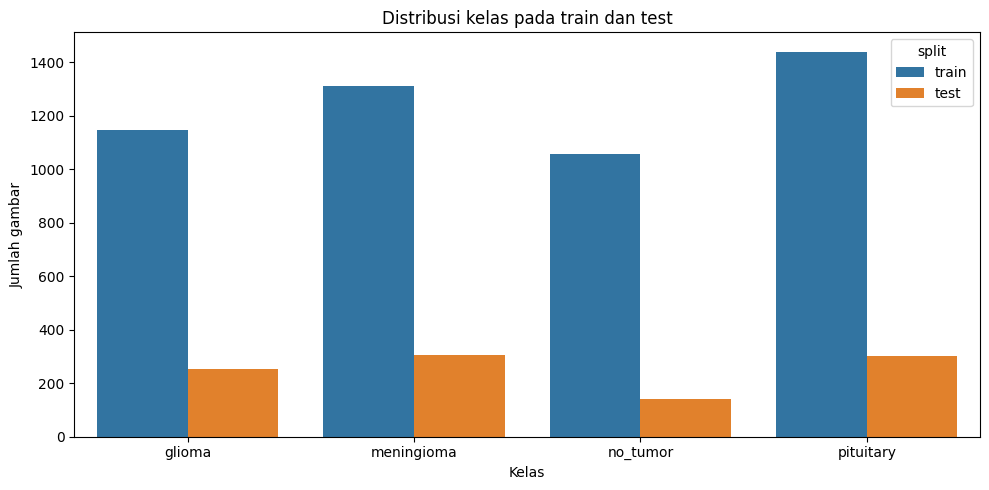

File rusak train: 0
File rusak test : 0


In [5]:
# Cell 5 - Grafik distribusi dan pemeriksaan file rusak
distribution = pd.concat([
    train_all_df.assign(split="train"),
    test_df.assign(split="test")
], ignore_index=True)

plt.figure(figsize=(10, 5))
sns.countplot(data=distribution, x="label", hue="split", order=CLASS_NAMES)
plt.title("Distribusi kelas pada train dan test")
plt.xlabel("Kelas")
plt.ylabel("Jumlah gambar")
plt.tight_layout()
plt.savefig(RUN_ROOT / "dataset_distribution.png", dpi=150)
plt.show()

def find_corrupt_images(df):
    corrupt = []
    for image_path in df["image_path"]:
        try:
            with Image.open(image_path) as image:
                image.verify()
        except Exception as error:
            corrupt.append({"image_path": image_path, "error": str(error)})
    return pd.DataFrame(corrupt)

corrupt_train_df = find_corrupt_images(train_all_df)
corrupt_test_df = find_corrupt_images(test_df)
corrupt_df = pd.concat([corrupt_train_df, corrupt_test_df], ignore_index=True)

print("File rusak train:", len(corrupt_train_df))
print("File rusak test :", len(corrupt_test_df))
if len(corrupt_df):
    display(corrupt_df.head())
    corrupt_df.to_csv(RUN_ROOT / "corrupt_images.csv", index=False)


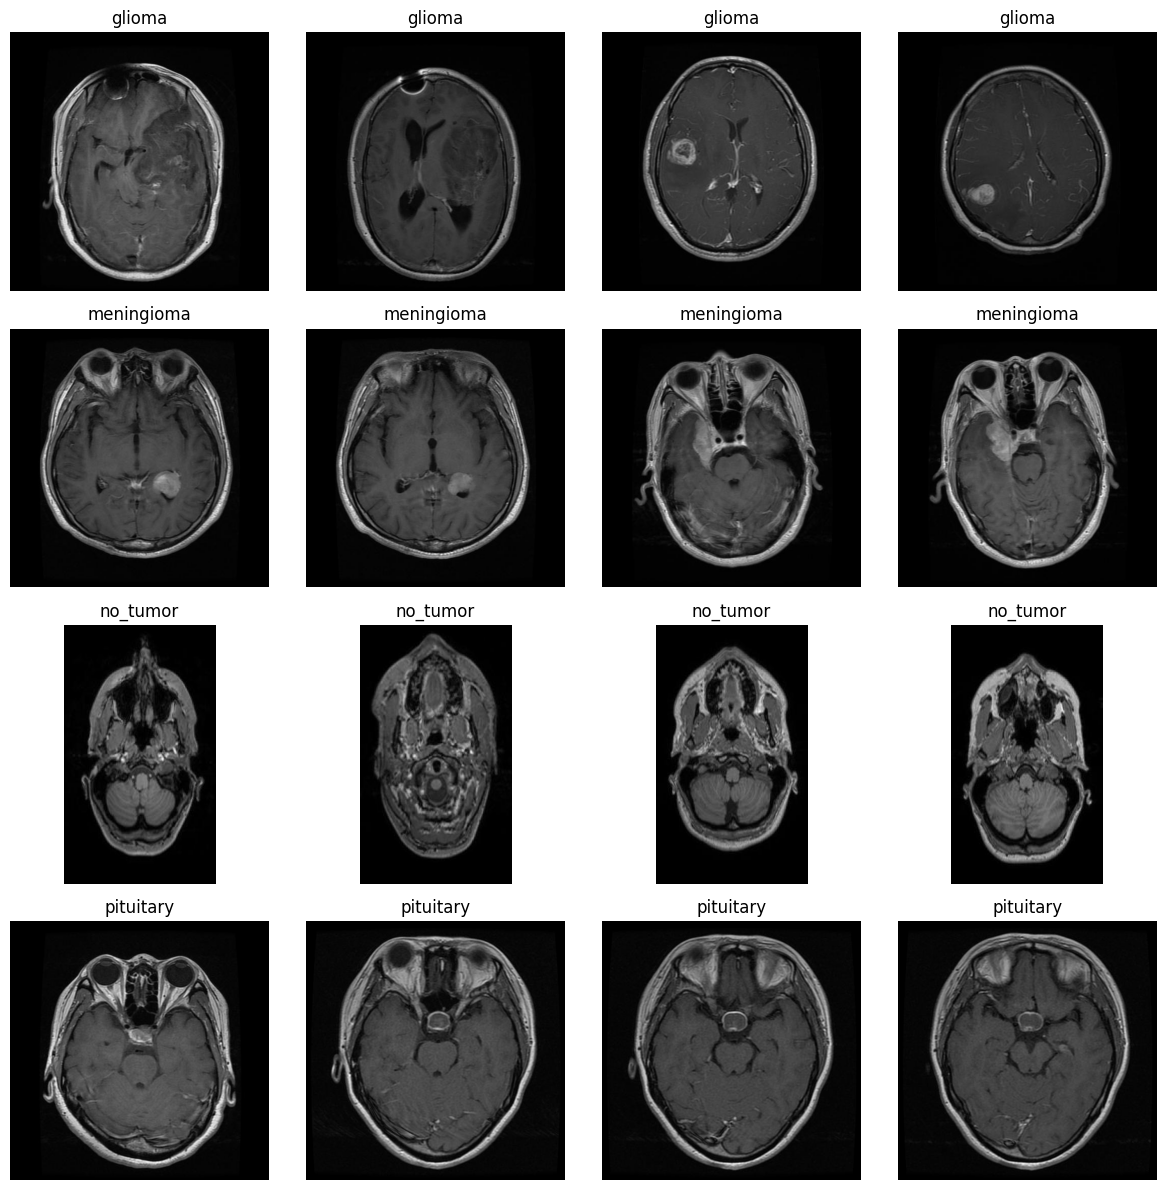

In [6]:
# Cell 6 - Menampilkan contoh gambar setiap kelas
fig, axes = plt.subplots(len(CLASS_NAMES), 4, figsize=(12, 12))
for row, class_name in enumerate(CLASS_NAMES):
    samples = train_all_df[train_all_df["label"] == class_name].head(4)
    for col in range(4):
        ax = axes[row, col]
        ax.axis("off")
        if col < len(samples):
            image = Image.open(samples.iloc[col]["image_path"]).convert("RGB")
            ax.imshow(image)
            ax.set_title(class_name)
plt.tight_layout()
plt.savefig(RUN_ROOT / "sample_images.png", dpi=150)
plt.show()


## 4. Pembagian data

Data train dibagi menjadi 80% train dan 20% validation secara stratified. Data test resmi tidak disentuh dan hanya dipakai pada evaluasi akhir.

In [7]:
# Cell 7 - Stratified split
train_df, val_df = train_test_split(
    train_all_df,
    test_size=VAL_SIZE,
    stratify=train_all_df["label"],
    random_state=RANDOM_SEED,
)

train_df = train_df.reset_index(drop=True)
val_df = val_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)

print("Train     :", len(train_df))
print("Validation:", len(val_df))
print("Test      :", len(test_df))

split_summary = pd.concat([
    train_df["label"].value_counts().rename("train"),
    val_df["label"].value_counts().rename("validation"),
    test_df["label"].value_counts().rename("test"),
], axis=1).fillna(0).astype(int)
display(split_summary)
split_summary.to_csv(RUN_ROOT / "split_summary.csv")


Train     : 3964
Validation: 991
Test      : 1000


,train,validation,test
label,,,
pituitary,1152,288,300
meningioma,1048,262,306
glioma,918,229,254
no_tumor,846,212,140


### Penyeimbangan kelas dengan SMOTE

SMOTE hanya diterapkan pada **data train** setelah pembagian train/validation, sehingga validation dan test tetap berisi gambar asli. Kelas minoritas dinaikkan sampai sama dengan kelas terbesar. Gambar sintetis disimpan di `RUN_ROOT/smote_train` dan asal induknya dicatat di `smote_sources.csv`. Matikan dengan `USE_SMOTE = False` di Cell 2.

In [ ]:
# Cell 7b - SMOTE pada data train
import sys
sys.path.insert(0, str(PROJECT_ROOT / "scripts"))
from smote_images import smote_oversample

train_real_counts = train_df["label"].value_counts()
if USE_SMOTE:
    train_df, smote_sources = smote_oversample(
        train_df,
        preprocess_fn=preprocess_brain_image,
        output_dir=RUN_ROOT / "smote_train",
        class_names=CLASS_NAMES,
        image_size=IMAGE_SIZE,
        k_neighbors=SMOTE_K_NEIGHBORS,
        same_plane=SMOTE_SAME_PLANE,
        seed=RANDOM_SEED,
    )
    smote_sources.to_csv(RUN_ROOT / "smote_sources.csv", index=False)
else:
    train_df = train_df.assign(synthetic=False)
train_df = train_df.reset_index(drop=True)

smote_summary = pd.concat([
    train_real_counts.rename("train_asli"),
    train_df[train_df["synthetic"]]["label"].value_counts().rename("train_sintetis"),
    train_df["label"].value_counts().rename("train_total"),
    val_df["label"].value_counts().rename("validation"),
    test_df["label"].value_counts().rename("test"),
], axis=1).fillna(0).astype(int).reindex(CLASS_NAMES)
display(smote_summary)
smote_summary.to_csv(RUN_ROOT / "split_summary_setelah_smote.csv")
print("USE_SMOTE:", USE_SMOTE, "| train total:", len(train_df), "| validation:", len(val_df), "| test:", len(test_df))


## 5. Preprocessing dan DataLoader

Augmentasi: horizontal flip, rotasi/translasi/skala kecil (`AUG_ROTATION_DEGREES`, untuk citra yang miring), serta gamma, brightness, dan contrast yang lebih lebar (`AUG_STRONG_INTENSITY`, untuk variasi protokol MRI). Semua diatur dari Cell 2 dan berasal dari analisis kesalahan di `results/error_feature_analysis/TEMUAN.md`.

In [8]:
# Cell 8 - Dataset, transform, dan DataLoader
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]

def make_transforms(image_size, training=False):
    if training:
        return transforms.Compose([
            transforms.Lambda(lambda image: preprocess_brain_image(image, image_size)),
            transforms.RandomResizedCrop(image_size, scale=(0.92, 1.0), ratio=(0.95, 1.05)),
            transforms.RandomHorizontalFlip(p=0.5),
            transforms.RandomAffine(
                degrees=AUG_ROTATION_DEGREES,
                translate=(AUG_TRANSLATE, AUG_TRANSLATE),
                scale=AUG_SCALE,
                fill=0,
            ),
            RandomGamma(
                probability=0.50 if AUG_STRONG_INTENSITY else 0.35,
                gamma_range=(0.70, 1.40) if AUG_STRONG_INTENSITY else (0.85, 1.15),
            ),
            transforms.ColorJitter(
                brightness=0.20 if AUG_STRONG_INTENSITY else 0.10,
                contrast=0.25 if AUG_STRONG_INTENSITY else 0.10,
            ),
            transforms.RandomApply([transforms.GaussianBlur(kernel_size=3, sigma=(0.1, 1.0))], p=0.15),
            transforms.ToTensor(),
            AddGaussianNoise(probability=0.20, standard_deviation=0.015),
            transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
        ])
    return transforms.Compose([
        transforms.Lambda(lambda image: preprocess_brain_image(image, image_size)),
        transforms.ToTensor(),
        transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
    ])

class BrainTumorDataset(Dataset):
    def __init__(self, dataframe, transform=None, image_size=IMAGE_SIZE):
        self.dataframe = dataframe.reset_index(drop=True).copy()
        self.transform = transform
        self.image_size = int(image_size)
        if self.image_size <= 0:
            raise ValueError(f"image_size harus positif, bukan {image_size}.")
        missing = [
            str(path) for path in self.dataframe["image_path"]
            if not Path(path).is_file()
        ]
        if missing:
            examples = "\n".join(missing[:5])
            raise FileNotFoundError(
                f"Dataset {len(missing)} file hilang saat DataLoader dibuat.\n"
                f"Contoh:\n{examples}\n"
                "Jalankan ulang Cell 4 untuk membangun manifest terbaru."
            )

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, index):
        row = self.dataframe.iloc[index]
        image_path = Path(row["image_path"])
        try:
            with Image.open(image_path) as source_image:
                image = source_image.convert("RGB")
        except Exception as error:
            raise RuntimeError(f"Gagal membaca gambar: {image_path}. {error}") from error
        if self.transform is None:
            raise ValueError(
                "Transform wajib diberikan agar gambar diubah menjadi tensor berukuran tetap."
            )
        image = self.transform(image)
        if not isinstance(image, torch.Tensor):
            raise TypeError(
                f"Transform menghasilkan {type(image).__name__}, bukan torch.Tensor untuk {image_path}."
            )
        expected_shape = (3, self.image_size, self.image_size)
        if tuple(image.shape) != expected_shape:
            raise RuntimeError(
                f"Preprocessing menghasilkan {tuple(image.shape)} untuk {image_path}; "
                f"ukuran wajib {expected_shape}."
            )
        return image, int(row["label_id"]), str(image_path)

def make_loaders(image_size=IMAGE_SIZE, batch_size=BATCH_SIZE, train_frame=None, val_frame=None, test_frame=None):
    image_size = int(image_size)
    batch_size = int(batch_size)
    if image_size <= 0 or batch_size <= 0:
        raise ValueError("image_size dan batch_size harus berupa bilangan positif.")

    frames = {
        "train": train_frame if train_frame is not None else globals().get("train_df"),
        "validation": val_frame if val_frame is not None else globals().get("val_df"),
        "test": test_frame if test_frame is not None else globals().get("test_df"),
    }
    missing_frames = [name for name, frame in frames.items() if frame is None]
    if missing_frames:
        raise RuntimeError(
            "DataFrame belum tersedia untuk: " + ", ".join(missing_frames) + ". "
            "Jalankan Cell 7 (Stratified split) terlebih dahulu atau kirim frame secara eksplisit."
        )

    train_frame = validate_manifest_paths(frames["train"], "train_loader")
    val_frame = validate_manifest_paths(frames["validation"], "val_loader")
    test_frame = validate_manifest_paths(frames["test"], "test_loader")
    train_dataset = BrainTumorDataset(train_frame, make_transforms(image_size, True), image_size=image_size)
    val_dataset = BrainTumorDataset(val_frame, make_transforms(image_size, False), image_size=image_size)
    test_dataset = BrainTumorDataset(test_frame, make_transforms(image_size, False), image_size=image_size)

    common = {
        "num_workers": NUM_WORKERS,
        "pin_memory": PIN_MEMORY,
    }
    train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True, **common)
    val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False, **common)
    test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False, **common)
    return train_loader, val_loader, test_loader

train_loader, val_loader, test_loader = make_loaders()
images, labels, paths = next(iter(train_loader))
print("Bentuk batch gambar:", images.shape)
print("Bentuk label       :", labels.shape)
print("Contoh path        :", paths[0])

Bentuk batch gambar: torch.Size([16, 3, 224, 224])
Bentuk label       : torch.Size([16])
Contoh path        : E:\CNN(Tumor otak)\Code Program\brisc2025-v6\brisc2025\classification_task\train\meningioma\brisc2025_train_01590_me_co_t1.jpg


## 6. Model EdgeNeXt

Jika timm belum terpasang, cell ini akan memberikan instruksi instalasi. Notebook tidak otomatis memasang library agar environment penelitian tidak berubah tanpa persetujuan.

In [9]:
# Cell 9 - Membuat model EdgeNeXt
def create_edgenext(model_name=MODEL_NAME, num_classes=NUM_CLASSES, pretrained=USE_PRETRAINED, drop_rate=0.0):
    if timm is None:
        raise ImportError(
            "Library timm belum terpasang. Jalankan pada terminal Python 3.10:\n"
            "python -m pip install timm"
        )

    available_models = timm.list_models("*edgenext*")
    if model_name not in available_models:
        print("Model yang tersedia:", available_models)
        raise ValueError(
            f"{model_name} tidak tersedia pada versi timm ini. "
            "Gunakan salah satu nama dari daftar di atas."
        )

    try:
        model = timm.create_model(
            model_name,
            pretrained=pretrained,
            num_classes=num_classes,
            drop_rate=drop_rate,
        )
    except TypeError:
        model = timm.create_model(
            model_name,
            pretrained=pretrained,
            num_classes=num_classes,
        )
    return model

def count_parameters(model):
    total = sum(parameter.numel() for parameter in model.parameters())
    trainable = sum(parameter.numel() for parameter in model.parameters() if parameter.requires_grad)
    return total, trainable

def model_size_mb(model_path):
    return round(Path(model_path).stat().st_size / 1024**2, 4)

if timm is not None:
    print("Model EdgeNeXt yang tersedia:", timm.list_models("*edgenext*")[:20])
    preview_model = create_edgenext()
    total_params, trainable_params = count_parameters(preview_model)
    print("Total parameter   :", f"{total_params:,}")
    print("Parameter trainable:", f"{trainable_params:,}")
    del preview_model
else:
    print("timm belum terpasang. Training belum dapat dimulai.")


Model EdgeNeXt yang tersedia: ['edgenext_base', 'edgenext_small', 'edgenext_small_rw', 'edgenext_x_small', 'edgenext_xx_small']
Total parameter   : 1,158,892
Parameter trainable: 1,158,892


## 7. Fungsi training dan evaluasi

In [10]:
# Cell 10 - Fungsi training
def run_epoch(model, loader, criterion, optimizer=None):
    is_training = optimizer is not None
    model.train(is_training)

    total_loss = 0.0
    all_targets, all_predictions = [], []

    for images, targets, _ in loader:
        images = images.to(DEVICE, non_blocking=PIN_MEMORY)
        targets = targets.to(DEVICE, non_blocking=PIN_MEMORY)

        if is_training:
            optimizer.zero_grad(set_to_none=True)

        with torch.set_grad_enabled(is_training):
            logits = model(images)
            loss = criterion(logits, targets)
            if is_training:
                loss.backward()
                torch.nn.utils.clip_grad_norm_(
                    model.parameters(),
                    max_norm=1.0,
                )
                optimizer.step()

        total_loss += loss.item() * images.size(0)
        all_targets.extend(targets.detach().cpu().numpy())
        all_predictions.extend(logits.argmax(dim=1).detach().cpu().numpy())

    average_loss = total_loss / len(loader.dataset)
    accuracy = accuracy_score(all_targets, all_predictions)
    _, _, macro_f1, _ = precision_recall_fscore_support(
        all_targets, all_predictions, average="macro", zero_division=0
    )
    return average_loss, accuracy, macro_f1

def fit_model(model, train_loader, val_loader, config, save_dir):
    save_dir = Path(save_dir)
    save_dir.mkdir(parents=True, exist_ok=True)

    model = model.to(DEVICE)
    criterion = nn.CrossEntropyLoss(
        label_smoothing=config.get("label_smoothing", 0.0)
    )
    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=config["learning_rate"],
        weight_decay=config["weight_decay"],
    )
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer, 
        mode="max", 
        factor=0.5, 
        patience=1,
        threshold=1e-3,
        threshold_mode="abs",
        cooldown=1,
        min_lr=1e-6
    )

    if torch.cuda.is_available():
        torch.cuda.reset_peak_memory_stats()

    history = []
    best_f1 = -1.0
    best_state = None
    patience_counter = 0
    start_time = time.perf_counter()
    ram_before = process_ram_mb()

    for epoch in range(1, config["epochs"] + 1):
        train_loss, train_acc, train_f1 = run_epoch(model, train_loader, criterion, optimizer)
        val_loss, val_acc, val_f1 = run_epoch(model, val_loader, criterion)
        scheduler.step(val_f1)

        row = {
            "epoch": epoch,
            "train_loss": train_loss,
            "train_accuracy": train_acc,
            "train_macro_f1": train_f1,
            "val_loss": val_loss,
            "val_accuracy": val_acc,
            "val_macro_f1": val_f1,
            "learning_rate": optimizer.param_groups[0]["lr"],
        }
        history.append(row)
        print(
            f"Epoch {epoch:02d}/{config['epochs']} | "
            f"train_loss={train_loss:.4f} | val_loss={val_loss:.4f} | "
            f"val_acc={val_acc:.4f} | val_macro_f1={val_f1:.4f}"
        )

        if val_f1 > best_f1:
            best_f1 = val_f1
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
            patience_counter = 0
        else:
            patience_counter += 1
            if patience_counter >= config["early_stopping_patience"]:
                print("Early stopping aktif.")
                break

    elapsed = time.perf_counter() - start_time
    model.load_state_dict(best_state)
    model_path = save_dir / "best_model.pt"
    torch.save({
        "model_state_dict": model.state_dict(),
        "config": config,
        "class_names": CLASS_NAMES,
        "model_name": config["model_name"],
    }, model_path)

    history_df = pd.DataFrame(history)
    history_df.to_csv(save_dir / "history.csv", index=False)
    total_params, trainable_params = count_parameters(model)

    resource = {
        "training_seconds": elapsed,
        "process_ram_before_mb": ram_before,
        "process_ram_after_mb": process_ram_mb(),
        "peak_gpu_memory_mb": gpu_memory_mb(),
        "total_parameters": total_params,
        "trainable_parameters": trainable_params,
        "model_file_mb": model_size_mb(model_path),
        "best_validation_macro_f1": best_f1,
    }
    save_json(resource, save_dir / "resource_metrics.json")
    save_json(config, save_dir / "config.json")

    history_df.plot(
        x="epoch",
        y=["train_loss", "val_loss"],
        marker="o",
        title="Loss training",
        figsize=(8, 4),
    )
    plt.tight_layout()
    plt.savefig(save_dir / "loss_curve.png", dpi=150)
    plt.show()

    history_df.plot(
        x="epoch",
        y=["train_accuracy", "val_accuracy", "val_macro_f1"],
        marker="o",
        title="Accuracy dan macro F1",
        figsize=(8, 4),
    )
    plt.tight_layout()
    plt.savefig(save_dir / "metric_curve.png", dpi=150)
    plt.show()

    return {
        "model": model,
        "model_path": model_path,
        "history": history_df,
        "resource": resource,
        "config": config,
    }


In [11]:
# Cell 11 - Fungsi evaluasi test
@torch.no_grad()
def predict_probabilities(model, images, use_tta=None):
    """Softmax; dengan TTA = rata-rata gambar asli dan flip horizontal."""
    use_tta = USE_TTA if use_tta is None else use_tta
    probabilities = torch.softmax(model(images), dim=1)
    if use_tta:
        probabilities = probabilities + torch.softmax(model(torch.flip(images, dims=[3])), dim=1)
        probabilities = probabilities / 2
    return probabilities

@torch.no_grad()
def compute_review_threshold(model, loader, flag_rate=None, use_tta=None):
    """Ambang confidence = kuantil `flag_rate` pada VALIDATION (bukan test)."""
    flag_rate = REVIEW_FLAG_RATE if flag_rate is None else flag_rate
    model.eval()
    confidences = []
    for images, _, _ in loader:
        images = images.to(DEVICE, non_blocking=PIN_MEMORY)
        confidences.append(predict_probabilities(model, images, use_tta).max(dim=1).values.cpu().numpy())
    return float(np.quantile(np.concatenate(confidences), flag_rate))

@torch.no_grad()
def evaluate_model(model, loader, split_name, save_dir, metric_labels=None,
                   use_tta=None, review_threshold_loader=None):
    use_tta = USE_TTA if use_tta is None else use_tta
    model.eval()
    if review_threshold_loader is not None:
        review_threshold = compute_review_threshold(model, review_threshold_loader, use_tta=use_tta)
        threshold_source = f"validation_quantile_{REVIEW_FLAG_RATE}"
    else:
        review_threshold = REVIEW_THRESHOLD_FALLBACK
        threshold_source = "fallback_constant"
    if torch.cuda.is_available():
        torch.cuda.synchronize()
    start_time = time.perf_counter()

    all_targets, all_predictions, all_probabilities, all_paths = [], [], [], []
    for images, targets, paths in loader:
        images = images.to(DEVICE, non_blocking=PIN_MEMORY)
        probabilities = predict_probabilities(model, images, use_tta)
        predictions = probabilities.argmax(dim=1)

        all_targets.extend(targets.numpy())
        all_predictions.extend(predictions.cpu().numpy())
        all_probabilities.append(probabilities.cpu().numpy())
        all_paths.extend(paths)

    if torch.cuda.is_available():
        torch.cuda.synchronize()
    inference_seconds = time.perf_counter() - start_time

    y_true = np.asarray(all_targets)
    y_pred = np.asarray(all_predictions)
    y_prob = np.concatenate(all_probabilities, axis=0)
    metric_labels = list(range(NUM_CLASSES)) if metric_labels is None else list(metric_labels)
    metric_class_names = [CLASS_NAMES[index] for index in metric_labels]

    precision, recall, f1, _ = precision_recall_fscore_support(
        y_true, y_pred, labels=metric_labels, zero_division=0
    )
    metrics = {
        "accuracy": accuracy_score(y_true, y_pred),
        "evaluated_classes": metric_class_names,
        "precision_macro": float(np.mean(precision)),
        "recall_macro": float(np.mean(recall)),
        "macro_f1": float(np.mean(f1)),
        "inference_seconds": inference_seconds,
        "inference_ms_per_image": inference_seconds / len(y_true) * 1000,
        "tta": bool(use_tta),
    }

    auc_by_class = {}
    for class_id in metric_labels:
        binary_targets = y_true == class_id
        auc_by_class[CLASS_NAMES[class_id]] = (
            float(roc_auc_score(binary_targets, y_prob[:, class_id]))
            if np.unique(binary_targets).size == 2 else None
        )
    valid_auc = [value for value in auc_by_class.values() if value is not None]
    metrics["roc_auc_ovr_by_class"] = auc_by_class
    metrics["roc_auc_ovr_macro"] = (
        float(np.mean(valid_auc)) if len(valid_auc) == len(metric_labels) else None
    )

    report = classification_report(
        y_true,
        y_pred,
        labels=metric_labels,
        target_names=metric_class_names,
        output_dict=True,
        zero_division=0,
    )
    report_df = pd.DataFrame(report).transpose()
    report_df.to_csv(Path(save_dir) / f"classification_report_{split_name}.csv")

    cm = confusion_matrix(y_true, y_pred, labels=list(range(NUM_CLASSES)))
    plt.figure(figsize=(7, 6))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
                xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES)
    plt.xlabel("Prediksi")
    plt.ylabel("Label sebenarnya")
    plt.title(f"Confusion matrix - {split_name}")
    plt.tight_layout()
    plt.savefig(Path(save_dir) / f"confusion_matrix_{split_name}.png", dpi=150)
    plt.show()

    predictions_df = pd.DataFrame({
        "image_path": all_paths,
        "true_label": [CLASS_NAMES[i] for i in y_true],
        "predicted_label": [CLASS_NAMES[i] for i in y_pred],
        "correct": y_true == y_pred,
        "confidence": y_prob.max(axis=1),
    })
    for class_id, class_name in enumerate(CLASS_NAMES):
        predictions_df[f"prob_{class_name}"] = y_prob[:, class_id]
    predictions_df["needs_review"] = predictions_df["confidence"] < review_threshold
    flagged = predictions_df["needs_review"]
    errors = ~predictions_df["correct"]
    metrics.update({
        "review_threshold": review_threshold,
        "review_threshold_source": threshold_source,
        "review_flagged_count": int(flagged.sum()),
        "review_flagged_rate": float(flagged.mean()),
        "errors_total": int(errors.sum()),
        "errors_caught_by_review": int((flagged & errors).sum()),
        "accuracy_not_flagged": float(predictions_df.loc[~flagged, "correct"].mean()) if (~flagged).any() else None,
    })
    predictions_df.to_csv(Path(save_dir) / f"predictions_{split_name}.csv", index=False)
    save_json(metrics, Path(save_dir) / f"metrics_{split_name}.json")

    print(pd.Series(metrics))
    display(report_df)
    return {"metrics": metrics, "report": report_df, "predictions": predictions_df}


## 8. Training baseline

Baseline berarti EdgeNeXt digunakan dengan konfigurasi awal. Model terbaik dipilih berdasarkan validation macro F1-score.

Epoch 01/40 | train_loss=0.5407 | val_loss=0.2123 | val_acc=0.9395 | val_macro_f1=0.9412
Epoch 02/40 | train_loss=0.1780 | val_loss=0.1506 | val_acc=0.9556 | val_macro_f1=0.9571
Epoch 03/40 | train_loss=0.1244 | val_loss=0.1329 | val_acc=0.9596 | val_macro_f1=0.9605
Epoch 04/40 | train_loss=0.1084 | val_loss=0.1533 | val_acc=0.9627 | val_macro_f1=0.9641
Epoch 05/40 | train_loss=0.0764 | val_loss=0.1282 | val_acc=0.9687 | val_macro_f1=0.9694
Epoch 06/40 | train_loss=0.0585 | val_loss=0.1251 | val_acc=0.9717 | val_macro_f1=0.9727
Epoch 07/40 | train_loss=0.0595 | val_loss=0.1000 | val_acc=0.9728 | val_macro_f1=0.9730
Epoch 08/40 | train_loss=0.0658 | val_loss=0.1485 | val_acc=0.9697 | val_macro_f1=0.9704
Epoch 09/40 | train_loss=0.0234 | val_loss=0.1026 | val_acc=0.9808 | val_macro_f1=0.9816
Epoch 10/40 | train_loss=0.0205 | val_loss=0.1015 | val_acc=0.9818 | val_macro_f1=0.9825
Epoch 11/40 | train_loss=0.0233 | val_loss=0.1299 | val_acc=0.9788 | val_macro_f1=0.9794
Epoch 12/40 | train_l

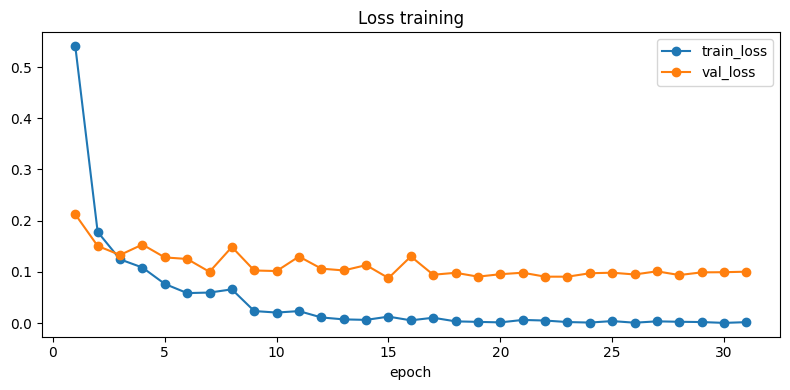

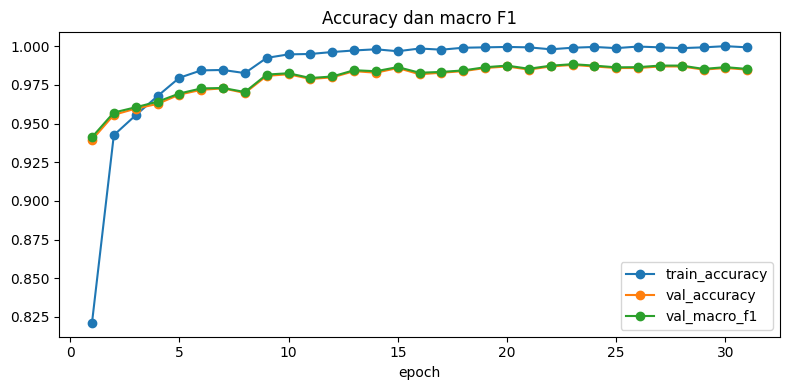

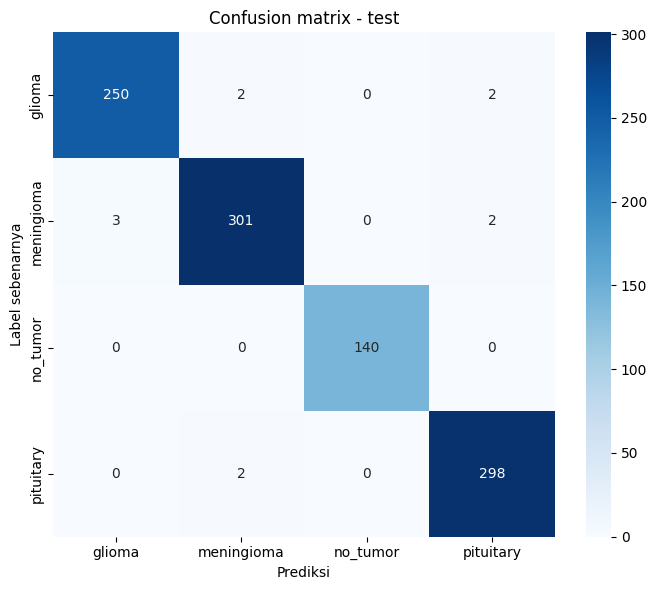

accuracy                                                               0.989
evaluated_classes                  [glioma, meningioma, no_tumor, pituitary]
precision_macro                                                     0.990446
recall_macro                                                        0.990311
macro_f1                                                            0.990374
inference_seconds                                                   37.13894
inference_ms_per_image                                              37.13894
tta                                                                     True
roc_auc_ovr_by_class       {'glioma': 0.9975934643558295, 'meningioma': 0...
roc_auc_ovr_macro                                                   0.998898
review_threshold                                                    0.997665
review_threshold_source                             validation_quantile_0.02
review_flagged_count                                                      21

,precision,recall,f1-score,support
glioma,0.988142,0.984252,0.986193,254.000
meningioma,0.986885,0.983660,0.985270,306.000
no_tumor,1.000000,1.000000,1.000000,140.000
pituitary,0.986755,0.993333,0.990033,300.000
accuracy,0.989000,0.989000,0.989000,0.989
macro avg,0.990446,0.990311,0.990374,1000.000
weighted avg,0.989002,0.989000,0.988996,1000.000


In [12]:
# Cell 12 - Training baseline
baseline_config = {
    "model_name": MODEL_NAME,
    "pretrained": USE_PRETRAINED,
    "drop_rate": 0.0,
    "label_smoothing": 0.0,
    "image_size": IMAGE_SIZE,
    "batch_size": BATCH_SIZE,
    "epochs": BASELINE_EPOCHS,
    "learning_rate": LEARNING_RATE,
    "weight_decay": WEIGHT_DECAY,
    "early_stopping_patience": EARLY_STOPPING_PATIENCE,
    "random_seed": RANDOM_SEED,
}

if timm is None:
    raise ImportError("timm belum terpasang. Pasang timm dahulu sebelum menjalankan training.")

seed_everything(RANDOM_SEED)
baseline_model = create_edgenext(
    model_name=baseline_config["model_name"],
    pretrained=baseline_config["pretrained"],
    drop_rate=baseline_config["drop_rate"],
)
baseline_result = fit_model(
    baseline_model,
    train_loader,
    val_loader,
    baseline_config,
    BASELINE_DIR,
)
baseline_evaluation = evaluate_model(
    baseline_result["model"],
    test_loader,
    "test",
    BASELINE_DIR,
    review_threshold_loader=val_loader,
)


## 9. Tuning EdgeNeXt

Tuning tetap menggunakan EdgeNeXt yang sama. Tidak ada model pembanding kedua. Pencarian dibuat terbatas agar dapat dijalankan pada laptop. Model dari trial terbaik langsung dipakai untuk evaluasi final tanpa training ulang setelah tuning.


===== TUNING TRIAL 1/1 =====


Epoch 01/50 | train_loss=0.7338 | val_loss=0.4764 | val_acc=0.9405 | val_macro_f1=0.9422
Epoch 02/50 | train_loss=0.4629 | val_loss=0.4857 | val_acc=0.9294 | val_macro_f1=0.9301
Epoch 03/50 | train_loss=0.4273 | val_loss=0.4406 | val_acc=0.9576 | val_macro_f1=0.9589
Epoch 04/50 | train_loss=0.4203 | val_loss=0.5151 | val_acc=0.9253 | val_macro_f1=0.9266
Epoch 05/50 | train_loss=0.4009 | val_loss=0.4122 | val_acc=0.9748 | val_macro_f1=0.9756
Epoch 06/50 | train_loss=0.3885 | val_loss=0.3935 | val_acc=0.9828 | val_macro_f1=0.9836
Epoch 07/50 | train_loss=0.3903 | val_loss=0.4183 | val_acc=0.9667 | val_macro_f1=0.9672
Epoch 08/50 | train_loss=0.3807 | val_loss=0.4111 | val_acc=0.9768 | val_macro_f1=0.9774
Epoch 09/50 | train_loss=0.3637 | val_loss=0.3944 | val_acc=0.9839 | val_macro_f1=0.9845
Epoch 10/50 | train_loss=0.3639 | val_loss=0.3919 | val_acc=0.9839 | val_macro_f1=0.9843
Epoch 11/50 | train_loss=0.3634 | val_loss=0.3974 | val_acc=0.9828 | val_macro_f1=0.9834
Epoch 12/50 | train_l

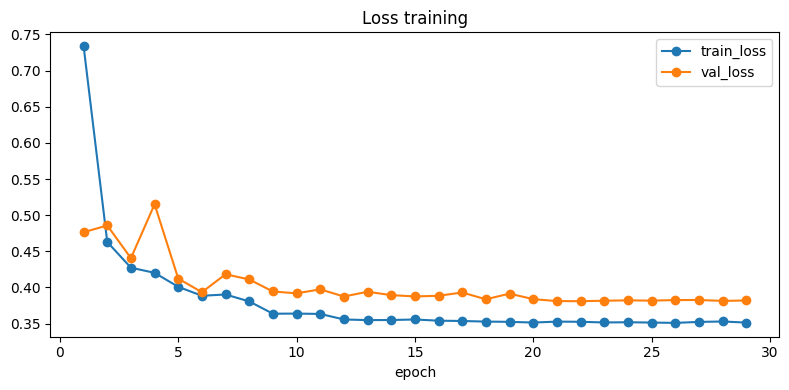

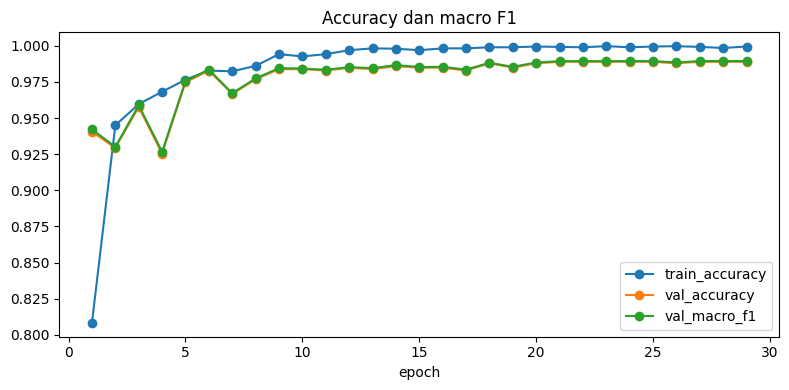

,model_name,pretrained,drop_rate,image_size,batch_size,epochs,learning_rate,weight_decay,label_smoothing,early_stopping_patience,random_seed,trial,best_validation_macro_f1,training_seconds
0,edgenext_xx_small,True,0.2,224,16,50,0.0001,0.0001,0.1,5,42,1,0.989444,5572.636503


Konfigurasi tuning terbaik:
{'model_name': 'edgenext_xx_small', 'pretrained': True, 'drop_rate': 0.2, 'image_size': 224, 'batch_size': 16, 'epochs': 50, 'learning_rate': 0.0001, 'weight_decay': 0.0001, 'label_smoothing': 0.1, 'early_stopping_patience': 5, 'random_seed': 42}


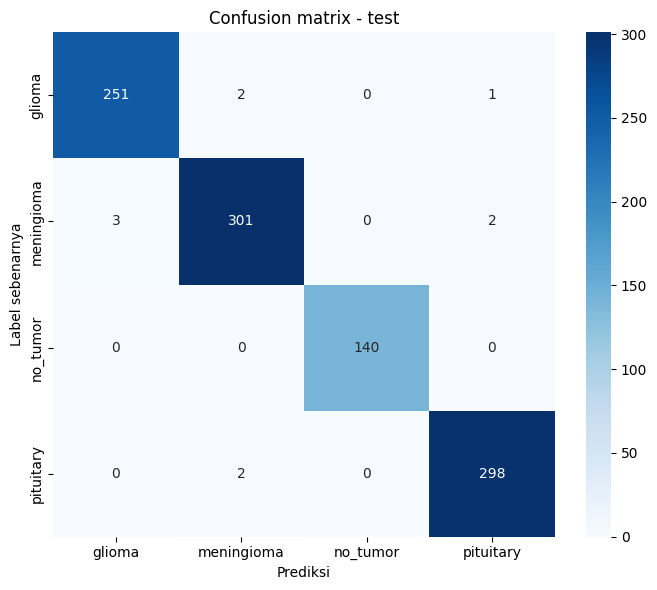

accuracy                                                                0.99
evaluated_classes                  [glioma, meningioma, no_tumor, pituitary]
precision_macro                                                     0.991277
recall_macro                                                        0.991296
macro_f1                                                            0.991285
inference_seconds                                                  26.297859
inference_ms_per_image                                             26.297859
tta                                                                     True
roc_auc_ovr_by_class       {'glioma': 0.9979365012349328, 'meningioma': 0...
roc_auc_ovr_macro                                                   0.998183
review_threshold                                                    0.885103
review_threshold_source                             validation_quantile_0.02
review_flagged_count                                                      12

,precision,recall,f1-score,support
glioma,0.988189,0.988189,0.988189,254.00
meningioma,0.986885,0.983660,0.985270,306.00
no_tumor,1.000000,1.000000,1.000000,140.00
pituitary,0.990033,0.993333,0.991681,300.00
accuracy,0.990000,0.990000,0.990000,0.99
macro avg,0.991277,0.991296,0.991285,1000.00
weighted avg,0.989997,0.990000,0.989997,1000.00


Tuning dan evaluasi final selesai tanpa retraining.
Model tuned: E:\CNN(Tumor otak)\Code Program\hasil_edgenext\20261119_011920\02_tuning\trial_1\best_model.pt


In [13]:
# Cell 13 - Tuning terbatas
required_names = [
    "MODEL_NAME",
    "USE_PRETRAINED",
    "IMAGE_SIZE",
    "BATCH_SIZE",
    "TUNING_EPOCHS",
    "MAX_TUNING_TRIALS",
    "RANDOM_SEED",
    "TUNING_DIR",
    "make_loaders",
    "create_edgenext",
    "fit_model",
    "seed_everything",
    "evaluate_model",
    "test_loader",
    "FINAL_DIR",
]
missing_names = [
    name for name in required_names
    if name not in globals()
]

if missing_names:
    raise RuntimeError(
        "Jalankan cell sebelumnya terlebih dahulu. "
        f"Variabel/fungsi yang belum tersedia: {missing_names}"
    )

if MAX_TUNING_TRIALS < 1:
    raise ValueError("MAX_TUNING_TRIALS harus minimal 1.")
tuning_space = [
    {
        "model_name": MODEL_NAME,
        "pretrained": USE_PRETRAINED,
        "drop_rate": 0.20,
        "image_size": IMAGE_SIZE,
        "batch_size": BATCH_SIZE,
        "epochs": TUNING_EPOCHS,
        "learning_rate": 1e-4,
        "weight_decay": 1e-4,
        "label_smoothing": 0.10,
        "early_stopping_patience": 5,
        "random_seed": RANDOM_SEED,
    },
][:MAX_TUNING_TRIALS]

tuning_rows = []
tuning_results = []
trial_model: nn.Module | None = None
trial_train_loader: DataLoader | None = None
trial_val_loader: DataLoader | None = None

for trial_index, trial_config in enumerate(tuning_space, start=1):
    seed_everything(RANDOM_SEED)
    print(f"\n===== TUNING TRIAL {trial_index}/{len(tuning_space)} =====")
    trial_dir = TUNING_DIR / f"trial_{trial_index:01d}"
    trial_train_loader, trial_val_loader, _ = make_loaders(
        image_size=trial_config["image_size"],
        batch_size=trial_config["batch_size"],
    )
    trial_model = create_edgenext(
        model_name=trial_config["model_name"],
        pretrained=trial_config["pretrained"],
        drop_rate=trial_config["drop_rate"],
    )
    trial_result = fit_model(
        trial_model,
        trial_train_loader,
        trial_val_loader,
        trial_config,
        trial_dir,
    )
    tuning_results.append(trial_result)
    tuning_rows.append({
        **trial_config,
        "trial": trial_index,
        "best_validation_macro_f1": trial_result["resource"]["best_validation_macro_f1"],
        "training_seconds": trial_result["resource"]["training_seconds"],
    })

tuning_df = pd.DataFrame(tuning_rows).sort_values(
    "best_validation_macro_f1", ascending=False
).reset_index(drop=True)
display(tuning_df)
tuning_df.to_csv(TUNING_DIR / "tuning_results.csv", index=False)
total_tuning_seconds = float(tuning_df["training_seconds"].sum())

best_trial_index = int(tuning_df.iloc[0]["trial"])
best_config = tuning_space[best_trial_index - 1].copy()
print("Konfigurasi tuning terbaik:")
print(best_config)

best_tuning_result = tuning_results[best_trial_index - 1]
final_config = best_config.copy()
final_result = best_tuning_result
final_evaluation = evaluate_model(
    final_result["model"],
    test_loader,
    split_name="test",
    save_dir=FINAL_DIR,
    review_threshold_loader=val_loader,
)
print("Tuning dan evaluasi final selesai tanpa retraining.")
print("Model tuned:", final_result["model_path"])

tuning_results.clear()
trial_model = None
trial_train_loader = None
trial_val_loader = None
gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()


## 10. Perbandingan baseline dan setelah tuning

In [14]:
# Cell 14 - Tabel perbandingan otomatis
required_names = ["baseline_evaluation", "final_evaluation", "baseline_result", "final_result", "total_tuning_seconds", "CLASS_NAMES", "COMPARISON_DIR"]
missing_names = [name for name in required_names if name not in globals()]
if missing_names:
    raise RuntimeError("Jalankan cell 1 sampai 13 terlebih dahulu. Variabel/fungsi yang belum tersedia: " + str(missing_names))

baseline_metrics = baseline_evaluation["metrics"]
final_metrics = final_evaluation["metrics"]

comparison = pd.DataFrame({
    "Metrik": [
        "Accuracy",
        "Precision macro",
        "Recall rata-rata",
        "Macro F1-score",
        "ROC-AUC OVR macro",
        "Waktu fit model utama (detik)",
        "Waktu trial tuning total (detik)",
        "Total waktu training termasuk tuning (detik)",
        "Waktu evaluasi end-to-end (detik)",
        "Waktu inferensi per gambar (ms)",
        "GPU memory puncak (MB)",
        "RAM proses setelah fit (MB)",
        "Jumlah parameter",
        "Ukuran model (MB)",
    ],
    "EdgeNeXt baseline": [
        baseline_metrics.get("accuracy"),
        baseline_metrics.get("precision_macro"),
        baseline_metrics.get("recall_macro"),
        baseline_metrics.get("macro_f1"),
        baseline_metrics.get("roc_auc_ovr_macro"),
        baseline_result["resource"]["training_seconds"],
        0.0,
        baseline_result["resource"]["training_seconds"],
        baseline_metrics["inference_seconds"],
        baseline_metrics["inference_ms_per_image"],
        baseline_result["resource"]["peak_gpu_memory_mb"],
        baseline_result["resource"]["process_ram_after_mb"],
        baseline_result["resource"]["total_parameters"],
        baseline_result["resource"]["model_file_mb"],
    ],
    "EdgeNeXt setelah tuning": [
        final_metrics.get("accuracy"),
        final_metrics.get("precision_macro"),
        final_metrics.get("recall_macro"),
        final_metrics.get("macro_f1"),
        final_metrics.get("roc_auc_ovr_macro"),
        final_result["resource"]["training_seconds"],
        total_tuning_seconds,
        total_tuning_seconds + final_result["resource"]["training_seconds"],
        final_metrics["inference_seconds"],
        final_metrics["inference_ms_per_image"],
        final_result["resource"]["peak_gpu_memory_mb"],
        final_result["resource"]["process_ram_after_mb"],
        final_result["resource"]["total_parameters"],
        final_result["resource"]["model_file_mb"],
    ],
})

display(comparison)
comparison.to_csv(COMPARISON_DIR / "baseline_vs_tuning.csv", index=False)

print("\nKESIMPULAN OTOMATIS")
delta_accuracy = final_metrics["accuracy"] - baseline_metrics["accuracy"]
delta_f1 = final_metrics["macro_f1"] - baseline_metrics["macro_f1"]
print(f"Perubahan accuracy   : {delta_accuracy:+.4f}")
print(f"Perubahan macro F1   : {delta_f1:+.4f}")
print("Tuning berhasil berdasarkan macro F1:",
      "YA" if delta_f1 > 0 else "TIDAK MENINGKAT")
print("Waktu inferensi:",
      "bertambah" if final_metrics["inference_seconds"] > baseline_metrics["inference_seconds"] else "berkurang/tetap")

baseline_hard_class = baseline_evaluation["report"].loc[CLASS_NAMES, "recall"].idxmin()
final_hard_class = final_evaluation["report"].loc[CLASS_NAMES, "recall"].idxmin()
print("Kelas tersulit baseline       :", baseline_hard_class)
print("Kelas tersulit setelah tuning:", final_hard_class)


,Metrik,EdgeNeXt baseline,EdgeNeXt setelah tuning
0,Accuracy,9.890000e-01,9.900000e-01
1,Precision macro,9.904456e-01,9.912769e-01
2,Recall rata-rata,9.903114e-01,9.912956e-01
3,Macro F1-score,9.903741e-01,9.912849e-01
4,ROC-AUC OVR macro,9.988983e-01,9.981831e-01
5,Waktu fit model utama (detik),7.215505e+03,5.572637e+03
6,Waktu trial tuning total (detik),0.000000e+00,5.572637e+03
7,Total waktu training termasuk tuning (detik),7.215505e+03,1.114527e+04
8,Waktu evaluasi end-to-end (detik),3.713894e+01,2.629786e+01
9,Waktu inferensi per gambar (ms),3.713894e+01,2.629786e+01



KESIMPULAN OTOMATIS
Perubahan accuracy   : +0.0010
Perubahan macro F1   : +0.0009
Tuning berhasil berdasarkan macro F1: YA
Waktu inferensi: berkurang/tetap
Kelas tersulit baseline       : meningioma
Kelas tersulit setelah tuning: meningioma


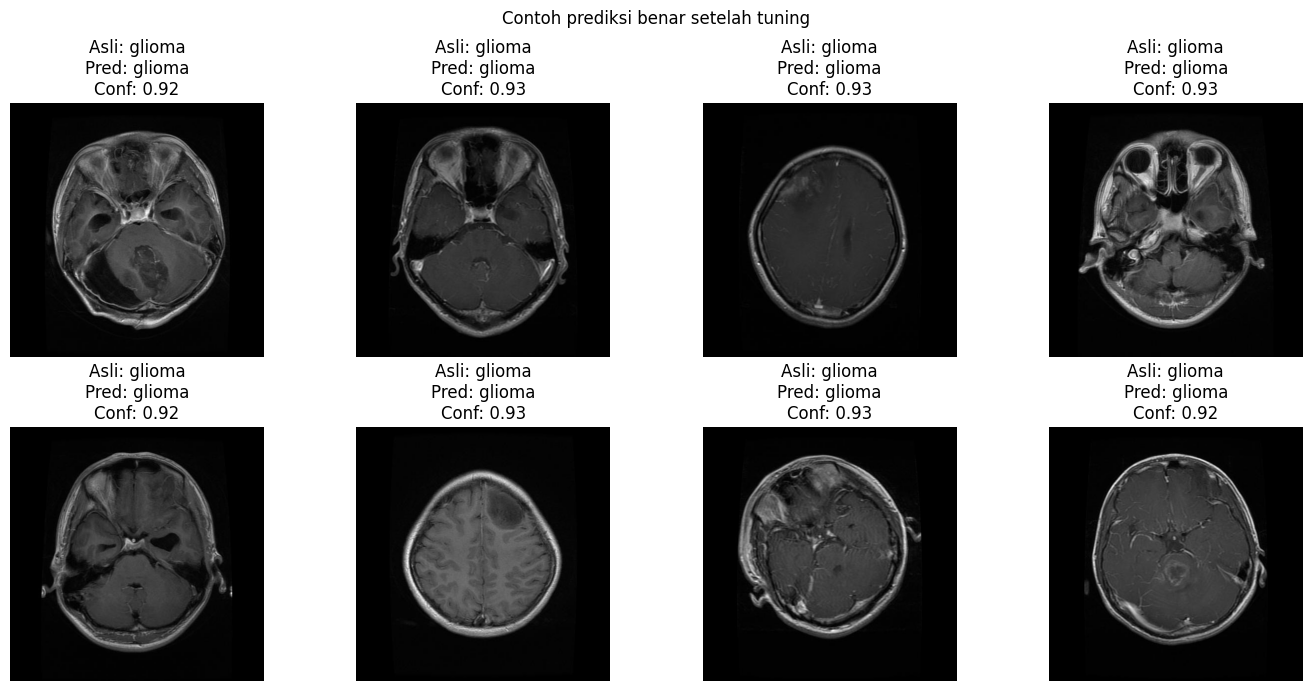

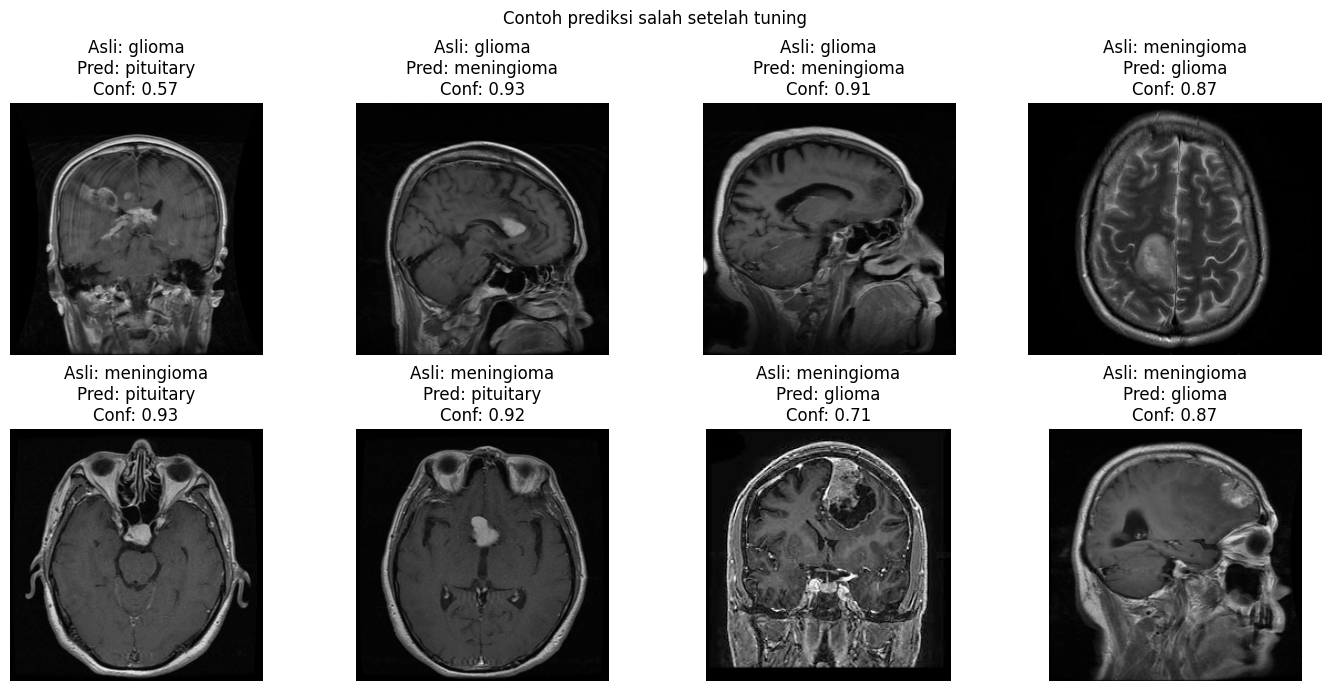

In [15]:
# Cell 15 - Contoh prediksi benar dan salah
required_names = ["final_evaluation", "COMPARISON_DIR", "Image", "np", "plt"]
missing_names = [name for name in required_names if name not in globals()]
if missing_names:
    raise RuntimeError("Jalankan cell 1 sampai 14 terlebih dahulu. Variabel/fungsi yang belum tersedia: " + str(missing_names))

def show_prediction_examples(predictions_df, title, correct=True, n=8):
    subset = predictions_df[predictions_df["correct"] == correct].head(n)
    if len(subset) == 0:
        print("Tidak ada contoh yang sesuai.")
        return

    columns = min(4, len(subset))
    rows = int(np.ceil(len(subset) / columns))
    fig, axes = plt.subplots(rows, columns, figsize=(14, 3.5 * rows))
    axes = np.array(axes).reshape(-1)

    for ax, (_, row) in zip(axes, subset.iterrows()):
        image = Image.open(row["image_path"]).convert("RGB")
        ax.imshow(image)
        ax.set_title(
            f"Asli: {row['true_label']}\n"
            f"Pred: {row['predicted_label']}\n"
            f"Conf: {row['confidence']:.2f}"
        )
        ax.axis("off")

    for ax in axes[len(subset):]:
        ax.axis("off")
    fig.suptitle(title)
    plt.tight_layout()
    output_name = "correct_examples.png" if correct else "wrong_examples.png"
    plt.savefig(COMPARISON_DIR / output_name, dpi=150)
    plt.show()

show_prediction_examples(
    final_evaluation["predictions"],
    "Contoh prediksi benar setelah tuning",
    correct=True,
)
show_prediction_examples(
    final_evaluation["predictions"],
    "Contoh prediksi salah setelah tuning",
    correct=False,
)


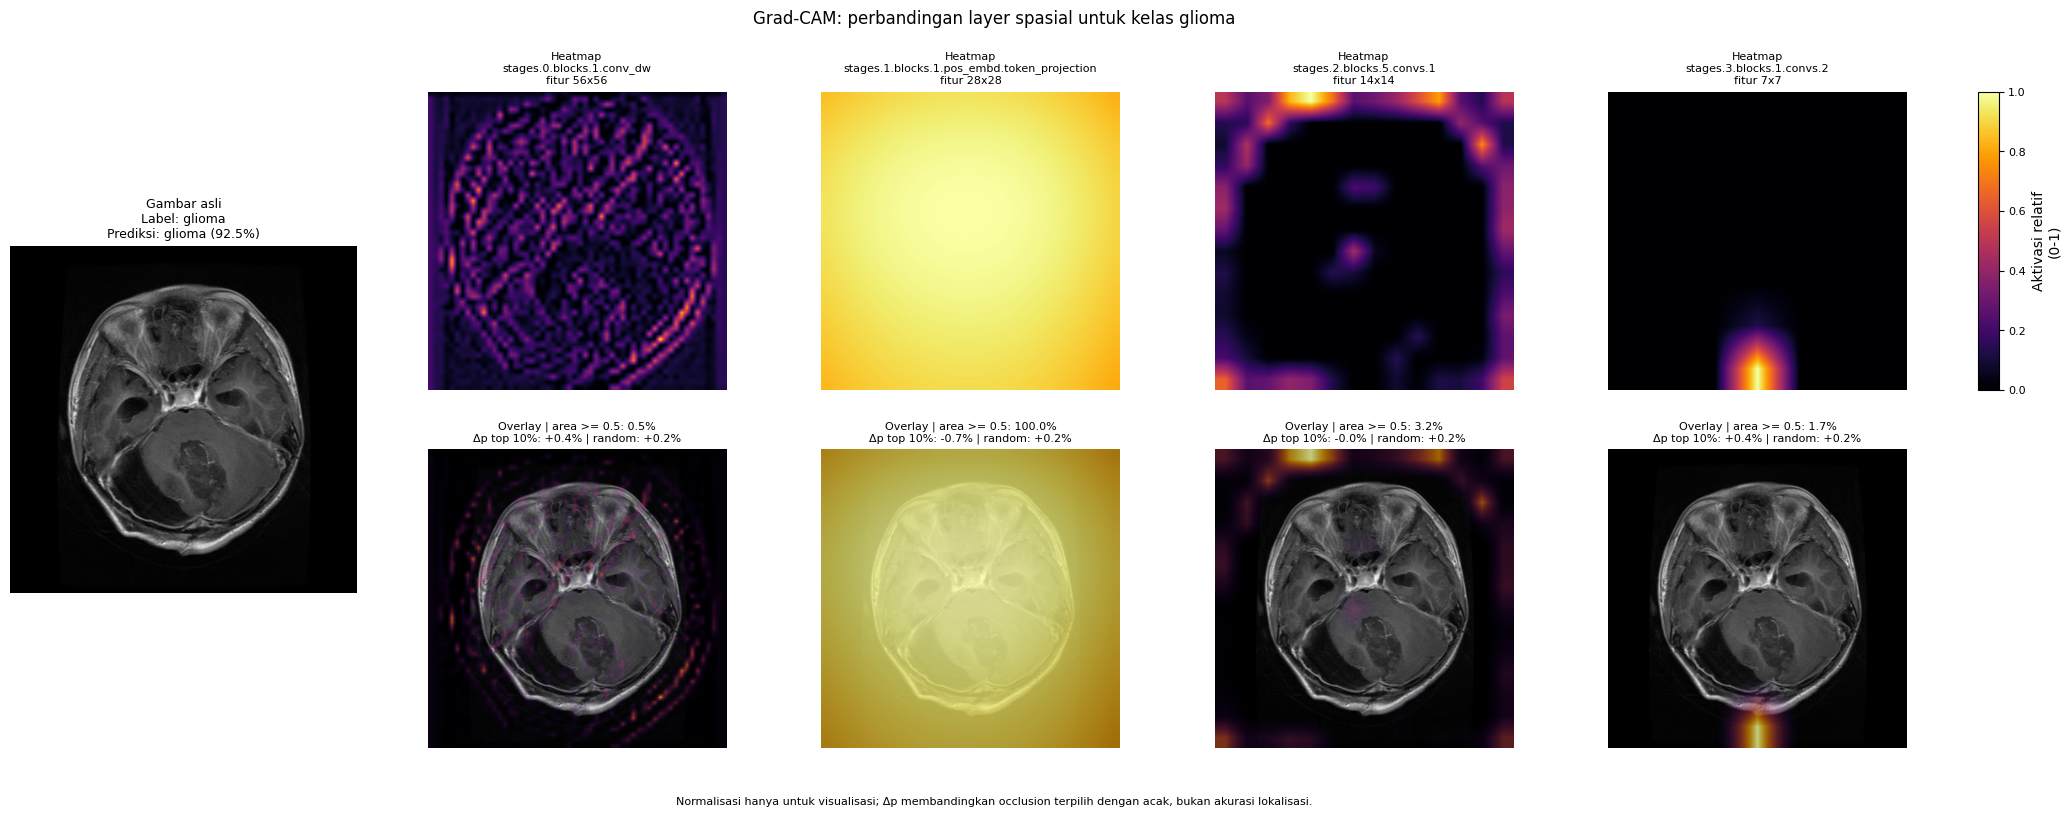

Prediksi: glioma
Confidence prediksi: 92.5%
Label sebenarnya: glioma
Layer dibandingkan: ['stages.0.blocks.1.conv_dw', 'stages.1.blocks.1.pos_embd.token_projection', 'stages.2.blocks.5.convs.1', 'stages.3.blocks.1.convs.2']
Perubahan confidence top-10% vs acak:
  stages.0.blocks.1.conv_dw: +0.4% vs +0.2% (lebih berpengaruh: True)
  stages.1.blocks.1.pos_embd.token_projection: -0.7% vs +0.2% (lebih berpengaruh: False)
  stages.2.blocks.5.convs.1: -0.0% vs +0.2% (lebih berpengaruh: False)
  stages.3.blocks.1.convs.2: +0.4% vs +0.2% (lebih berpengaruh: True)
Statistik layer tersimpan di: E:\CNN(Tumor otak)\Code Program\hasil_edgenext\20261119_011920\04_comparison\gradcam_example_layer_stats.csv


In [16]:
# Cell 16 - Grad-CAM dan perbandingan beberapa skala fitur
required_names = ["final_evaluation", "final_result", "make_transforms", "COMPARISON_DIR", "CLASS_NAMES", "torch", "nn", "np", "pd", "plt", "Image", "Path"]
missing_names = [name for name in required_names if name not in globals()]
if missing_names:
    raise RuntimeError("Jalankan cell 1 sampai 15 terlebih dahulu. Variabel/fungsi yang belum tersedia: " + str(missing_names))

def make_gradcam(model, image_path, transform, output_path, true_label=None, max_layers=4):
    was_training = model.training
    model.eval()
    output_path = Path(output_path)
    activations, gradients, handles = {}, {}, []

    def capture_activation(layer_name):
        def hook(_, __, output):
            if not isinstance(output, torch.Tensor) or output.ndim != 4:
                return
            if min(output.shape[-2:]) < 2:
                return
            activations[layer_name] = output

            def capture_gradient(gradient):
                gradients[layer_name] = gradient.detach()

            if output.requires_grad:
                output.register_hook(capture_gradient)
        return hook

    try:
        with Image.open(image_path) as source_image:
            original = source_image.convert("RGB")

        model_device = next(model.parameters()).device
        input_tensor = transform(original).unsqueeze(0).to(model_device)
        for layer_name, module in model.named_modules():
            if isinstance(module, nn.Conv2d):
                handles.append(module.register_forward_hook(capture_activation(layer_name)))

        model.zero_grad(set_to_none=True)
        with torch.enable_grad():
            logits = model(input_tensor)
            if logits.ndim != 2 or logits.shape[0] != 1:
                raise RuntimeError(f"Bentuk keluaran model tidak sesuai untuk satu gambar: {tuple(logits.shape)}")
            probabilities = torch.softmax(logits.detach(), dim=1)[0]
            predicted_class = int(probabilities.argmax().item())
            target_class = predicted_class
            target_confidence = float(probabilities[target_class].item())
            logits[0, target_class].backward()
        for handle in handles:
            handle.remove()
        handles.clear()

        if not activations:
            raise RuntimeError("Tidak ditemukan keluaran Conv2d spasial untuk Grad-CAM.")

        # Pilih layer terdalam pada setiap resolusi agar peta antar-tahap bisa dibandingkan.
        selected_layers = []
        seen_shapes = set()
        for layer_name in reversed(list(activations)):
            activation = activations[layer_name]
            spatial_shape = tuple(int(size) for size in activation.shape[-2:])
            if spatial_shape in seen_shapes:
                continue
            if layer_name not in gradients:
                continue
            selected_layers.append((layer_name, activation, gradients[layer_name]))
            seen_shapes.add(spatial_shape)
            if len(selected_layers) >= max_layers:
                break
        selected_layers.reverse()

        cam_records = []
        for layer_name, activation, gradient in selected_layers:
            feature_map = activation[0].detach()
            gradient_map = gradient[0].detach()
            channel_weights = gradient_map.mean(dim=(1, 2), keepdim=True)
            raw_cam = torch.relu((channel_weights * feature_map).sum(dim=0))
            raw_peak = raw_cam.max()
            if not torch.isfinite(raw_peak) or raw_peak.item() <= 1e-12:
                print(f"Layer dilewati karena CAM tidak memiliki aktivasi positif: {layer_name}")
                continue

            normalized_cam = raw_cam / raw_peak
            resized_cam = torch.nn.functional.interpolate(
                normalized_cam[None, None],
                size=original.size[::-1],
                mode="bilinear",
                align_corners=False,
            )[0, 0].detach().cpu().numpy()
            flat_cam = resized_cam.ravel()
            top_count = max(1, int(np.ceil(flat_cam.size * 0.10)))
            total_mass = float(flat_cam.sum())
            top_mass_share = float(
                np.partition(flat_cam, -top_count)[-top_count:].sum() / (total_mass + 1e-12)
            )
            cam_records.append({
                "layer": layer_name,
                "feature_height": int(feature_map.shape[-2]),
                "feature_width": int(feature_map.shape[-1]),
                "raw_cam_peak": float(raw_peak.item()),
                "area_at_or_above_0_5": float(np.mean(resized_cam >= 0.5)),
                "top_10_percent_activation_mass": top_mass_share,
                "cam": resized_cam,
            })

        if not cam_records:
            raise RuntimeError("Semua layer menghasilkan CAM kosong/tidak positif; heatmap tidak dibuat.")

        # Bandingkan penghapusan area CAM teratas dengan beberapa area acak berukuran sama.
        rng = np.random.default_rng(42)
        input_height, input_width = input_tensor.shape[-2:]
        pixel_count = input_height * input_width
        removed_count = max(1, int(np.ceil(pixel_count * 0.10)))

        def target_probability_drop(pixel_indices):
            mask = torch.zeros(pixel_count, dtype=torch.bool, device=model_device)
            indices = torch.as_tensor(pixel_indices, dtype=torch.long, device=model_device)
            mask[indices] = True
            mask = mask.reshape(input_height, input_width)
            occluded_input = input_tensor.detach().clone()
            occluded_input[0, :, mask] = 0.0
            with torch.no_grad():
                masked_probability = torch.softmax(model(occluded_input), dim=1)[0, target_class]
            return target_confidence - float(masked_probability.item())

        for record in cam_records:
            cam_tensor = torch.as_tensor(record["cam"], dtype=torch.float32, device=model_device)
            cam_tensor = torch.nn.functional.interpolate(
                cam_tensor[None, None],
                size=(input_height, input_width),
                mode="bilinear",
                align_corners=False,
            )[0, 0]
            top_indices = torch.topk(cam_tensor.reshape(-1), k=removed_count).indices.cpu().numpy()
            random_drops = [
                target_probability_drop(rng.choice(pixel_count, size=removed_count, replace=False))
                for _ in range(5)
            ]
            record["top10_probability_drop"] = target_probability_drop(top_indices)
            record["random_probability_drop_mean"] = float(np.mean(random_drops))
            record["random_probability_drop_std"] = float(np.std(random_drops))
            record["top10_more_influential_than_random"] = (
                record["top10_probability_drop"] > record["random_probability_drop_mean"]
            )

        output_path.parent.mkdir(parents=True, exist_ok=True)
        comparison_path = output_path.with_name(f"{output_path.stem}_layer_stats.csv")
        pd.DataFrame([
            {key: value for key, value in record.items() if key != "cam"}
            for record in cam_records
        ]).to_csv(comparison_path, index=False)

        figure = plt.figure(figsize=(4.0 * (len(cam_records) + 1) + 0.5, 8.2))
        grid = figure.add_gridspec(
            2,
            len(cam_records) + 2,
            width_ratios=[1.0] + [1.0] * len(cam_records) + [0.06],
            wspace=0.16,
            hspace=0.20,
        )
        original_axis = figure.add_subplot(grid[:, 0])
        original_axis.imshow(original)
        original_axis.axis("off")
        label_text = true_label if true_label is not None else "tidak tersedia"
        original_axis.set_title(
            f"Gambar asli\nLabel: {label_text}\n"
            f"Prediksi: {CLASS_NAMES[predicted_class]} ({target_confidence:.1%})",
            fontsize=9,
        )

        last_heatmap = None
        for column, record in enumerate(cam_records, start=1):
            cam = record["cam"]
            heatmap_axis = figure.add_subplot(grid[0, column])
            last_heatmap = heatmap_axis.imshow(
                cam, cmap="inferno", vmin=0.0, vmax=1.0, interpolation="bilinear"
            )
            heatmap_axis.axis("off")
            heatmap_axis.set_title(
                f"Heatmap\n{record['layer']}\n"
                f"fitur {record['feature_height']}x{record['feature_width']}",
                fontsize=8,
            )
            overlay_axis = figure.add_subplot(grid[1, column])
            overlay_axis.imshow(original)
            overlay_axis.imshow(
                cam,
                cmap="inferno",
                vmin=0.0,
                vmax=1.0,
                alpha=np.clip(cam * 0.80, 0.0, 0.80),
                interpolation="bilinear",
            )
            overlay_axis.axis("off")
            overlay_axis.set_title(
                f"Overlay | area >= 0.5: {record['area_at_or_above_0_5']:.1%}\n"
                f"Δp top 10%: {record['top10_probability_drop']:+.1%} | "
                f"random: {record['random_probability_drop_mean']:+.1%}",
                fontsize=8,
            )

        colorbar_axis = figure.add_subplot(grid[0, -1])
        if last_heatmap is None:
            raise RuntimeError("Tidak ada heatmap yang dapat ditampilkan.")
        colorbar = figure.colorbar(
            last_heatmap,
            cax=colorbar_axis,
            label="Aktivasi relatif\n(0-1)",
        )
        colorbar.ax.tick_params(labelsize=8)
        figure.suptitle(
            "Grad-CAM: perbandingan layer spasial untuk kelas "
            f"{CLASS_NAMES[predicted_class]}",
            fontsize=12,
        )
        figure.text(
            0.5,
            0.01,
            "Normalisasi hanya untuk visualisasi; Δp membandingkan occlusion terpilih dengan acak, bukan akurasi lokalisasi.",
            ha="center",
            fontsize=8,
        )
        figure.subplots_adjust(top=0.88, bottom=0.08, left=0.02, right=0.99)
        figure.savefig(output_path, dpi=180, bbox_inches="tight")
        if "agg" not in plt.get_backend().lower():
            plt.show()
        plt.close(figure)

        print("Prediksi:", CLASS_NAMES[predicted_class])
        print("Confidence prediksi:", f"{target_confidence:.1%}")
        print("Label sebenarnya:", label_text)
        print("Layer dibandingkan:", [record["layer"] for record in cam_records])
        print("Perubahan confidence top-10% vs acak:")
        for record in cam_records:
            print(
                f"  {record['layer']}: {record['top10_probability_drop']:+.1%} vs "
                f"{record['random_probability_drop_mean']:+.1%} "
                f"(lebih berpengaruh: {record['top10_more_influential_than_random']})"
            )
        print("Statistik layer tersimpan di:", comparison_path)
        return {
            "prediction": CLASS_NAMES[predicted_class],
            "confidence": target_confidence,
            "true_label": true_label,
            "layers": pd.DataFrame([
                {key: value for key, value in record.items() if key != "cam"}
                for record in cam_records
            ]),
            "image_path": output_path,
            "stats_path": comparison_path,
        }
    finally:
        for handle in handles:
            handle.remove()
        model.zero_grad(set_to_none=True)
        model.train(was_training)

gradcam_predictions = final_evaluation["predictions"]
if gradcam_predictions.empty:
    raise RuntimeError("Tidak ada prediksi test untuk contoh Grad-CAM.")
sample_row = gradcam_predictions.iloc[0]
gradcam_result = make_gradcam(
    final_result["model"],
    sample_row["image_path"],
    make_transforms(final_config["image_size"], False),
    COMPARISON_DIR / "gradcam_example.png",
    true_label=sample_row["true_label"],
)

In [17]:
# Cell 17 - Menyimpan konfigurasi dan ringkasan penelitian
required_names = ["PROJECT_ROOT", "DATA_DIR", "EXTERNAL_MENDELEY_ROOT", "EXTERNAL_MENDELEY_RAW", "EXTERNAL_AUDIT_SCRIPT", "OUTPUT_ROOT", "RUN_ROOT", "CLASS_NAMES", "RANDOM_SEED", "DEVICE", "baseline_config", "best_config", "final_config", "baseline_metrics", "final_metrics", "baseline_result", "final_result", "COMPARISON_DIR", "save_json"]
missing_names = [name for name in required_names if name not in globals()]
if missing_names:
    raise RuntimeError("Jalankan cell 1 sampai 16 terlebih dahulu. Variabel/fungsi yang belum tersedia: " + str(missing_names))

experiment_config = {
    "project_root": PROJECT_ROOT,
    "data_dir": DATA_DIR,
    "external_mendeley_root": EXTERNAL_MENDELEY_ROOT,
    "external_mendeley_raw": EXTERNAL_MENDELEY_RAW,
    "external_audit_script": EXTERNAL_AUDIT_SCRIPT,
    "output_root": OUTPUT_ROOT,
    "run_root": RUN_ROOT,
    "class_names": CLASS_NAMES,
    "random_seed": RANDOM_SEED,
    "device": DEVICE,
    "baseline_config": baseline_config,
    "best_tuning_config": best_config,
    "final_config": final_config,
    "data_quality_report": RUN_ROOT / "data_quality_report.csv",
    "limitation": (
        "Dataset berupa JPG 2D dan tidak menyediakan patient_id yang jelas. "
        "Evaluasi dilakukan pada tingkat gambar; pembersihan hash hanya menghapus duplikat identik, "
        "sehingga pemisahan pada tingkat pasien belum dapat dijamin. "
        "Dataset eksternal Mendeley tidak boleh digunakan sebagai evaluasi strict "
        "sebelum T1-kontras dan patient/group metadata diverifikasi."
    ),
}
save_json(experiment_config, COMPARISON_DIR / "experiment_config.json")

summary_text = f"""Ringkasan eksperimen EdgeNeXt BRISC2025

DATASET
- Lokasi: {DATA_DIR}
- Kelas: {", ".join(CLASS_NAMES)}
- Evaluasi: tingkat gambar karena patient_id tidak tersedia jelas

HASIL
- Accuracy baseline: {baseline_metrics.get("accuracy")}
- Accuracy setelah tuning: {final_metrics.get("accuracy")}
- Macro F1 baseline: {baseline_metrics.get("macro_f1")}
- Macro F1 setelah tuning: {final_metrics.get("macro_f1")}

File hasil tersimpan di:
{RUN_ROOT}
"""
(COMPARISON_DIR / "summary.txt").write_text(summary_text, encoding="utf-8")
print(summary_text)
print("Model baseline :", baseline_result["model_path"])
print("Model final    :", final_result["model_path"])


Ringkasan eksperimen EdgeNeXt BRISC2025

DATASET
- Lokasi: E:\CNN(Tumor otak)\Code Program\brisc2025-v6\brisc2025\classification_task
- Kelas: glioma, meningioma, no_tumor, pituitary
- Evaluasi: tingkat gambar karena patient_id tidak tersedia jelas

HASIL
- Accuracy baseline: 0.989
- Accuracy setelah tuning: 0.99
- Macro F1 baseline: 0.9903741413942
- Macro F1 setelah tuning: 0.9912848894809281

File hasil tersimpan di:
E:\CNN(Tumor otak)\Code Program\hasil_edgenext\20261119_011920

Model baseline : E:\CNN(Tumor otak)\Code Program\hasil_edgenext\20261119_011920\01_baseline\best_model.pt
Model final    : E:\CNN(Tumor otak)\Code Program\hasil_edgenext\20261119_011920\02_tuning\trial_1\best_model.pt


## 12. Audit overfitting

Audit ini membandingkan performa training dan validation untuk mendeteksi indikasi overfitting.

In [18]:
# Cell 18 - Audit overfitting
required_names = ["baseline_result", "final_result", "COMPARISON_DIR", "pd"]
missing_names = [name for name in required_names if name not in globals()]
if missing_names:
    raise RuntimeError("Jalankan cell 1 sampai 17 terlebih dahulu. Variabel/fungsi yang belum tersedia: " + str(missing_names))

def overfitting_summary(history_df, model_name):
    best_index = history_df["val_macro_f1"].idxmax()
    best_row = history_df.loc[best_index]
    last_row = history_df.iloc[-1]
    return {
        "model": model_name,
        "epochs_run": int(len(history_df)),
        "best_epoch": int(best_row["epoch"]),
        "best_val_macro_f1": float(best_row["val_macro_f1"]),
        "train_macro_f1_at_best": float(best_row["train_macro_f1"]),
        "train_val_f1_gap_at_best": float(best_row["train_macro_f1"] - best_row["val_macro_f1"]),
        "last_train_macro_f1": float(last_row["train_macro_f1"]),
        "last_val_macro_f1": float(last_row["val_macro_f1"]),
        "last_train_val_f1_gap": float(last_row["train_macro_f1"] - last_row["val_macro_f1"]),
    }

overfitting_audit = pd.DataFrame([
    overfitting_summary(baseline_result["history"], "baseline"),
    overfitting_summary(final_result["history"], "setelah_tuning"),
])
overfitting_audit.to_csv(COMPARISON_DIR / "overfitting_audit.csv", index=False)
display(overfitting_audit)

max_gap = float(overfitting_audit["last_train_val_f1_gap"].max())
if max_gap >= 0.10:
    conclusion = "Indikasi overfitting kuat: gap training-validation minimal 10 poin persentase."
elif max_gap >= 0.05:
    conclusion = "Indikasi overfitting sedang: gap training-validation minimal 5 poin persentase."
else:
    conclusion = "Tidak terlihat overfitting berat dari gap training-validation, tetapi validasi eksternal tetap wajib."
print(conclusion)
print("Catatan: akurasi tinggi pada test BRISC2025 tidak membuktikan model pasti generalisasi ke rumah sakit, scanner, atau dataset lain.")


,model,epochs_run,best_epoch,best_val_macro_f1,train_macro_f1_at_best,train_val_f1_gap_at_best,last_train_macro_f1,last_val_macro_f1,last_train_val_f1_gap
0,baseline,31,23,0.988351,0.999044,0.010693,0.999289,0.985293,0.013996
1,setelah_tuning,29,24,0.989444,0.999044,0.009601,0.999505,0.989444,0.010062


Tidak terlihat overfitting berat dari gap training-validation, tetapi validasi eksternal tetap wajib.
Catatan: akurasi tinggi pada test BRISC2025 tidak membuktikan model pasti generalisasi ke rumah sakit, scanner, atau dataset lain.


In [19]:
# Cell 19 - Audit dataset eksternal Mendeley dan verifikasi ukuran 224
required_names = ["EXTERNAL_AUDIT_SCRIPT", "EXTERNAL_MENDELEY_RAW", "PROJECT_ROOT", "RUN_ROOT", "IMAGE_SIZE", "train_all_df", "make_transforms", "Image"]
missing_names = [name for name in required_names if name not in globals()]
if missing_names:
    raise RuntimeError("Jalankan cell 1 sampai 18 terlebih dahulu. Variabel/fungsi yang belum tersedia: " + str(missing_names))

from importlib.util import module_from_spec, spec_from_file_location

if not EXTERNAL_AUDIT_SCRIPT.exists():
    raise FileNotFoundError(f"Script audit tidak ditemukan: {EXTERNAL_AUDIT_SCRIPT}")

audit_spec = spec_from_file_location("mendeley_external_audit", EXTERNAL_AUDIT_SCRIPT)
if audit_spec is None:
    raise ImportError(f"Tidak dapat membuat module spec untuk: {EXTERNAL_AUDIT_SCRIPT}")
audit_loader = audit_spec.loader
if audit_loader is None:
    raise ImportError(f"Loader audit tidak tersedia untuk: {EXTERNAL_AUDIT_SCRIPT}")
audit_module = module_from_spec(audit_spec)
audit_loader.exec_module(audit_module)

BRISC_MANIFEST_CANDIDATES = [
    PROJECT_ROOT / "brisc2025-v6" / "brisc2025" / "manifest.csv",
    PROJECT_ROOT.parent / "brisc2025-v6" / "brisc2025" / "manifest.csv",
]
BRISC_MANIFEST = next((path for path in BRISC_MANIFEST_CANDIDATES if path.exists()), None)
if BRISC_MANIFEST is None:
    raise FileNotFoundError("Manifest BRISC2025 tidak ditemukan.")

EXTERNAL_AUDIT_DIR = RUN_ROOT / "05_external_mendeley_audit"
external_raw_df = audit_module.scan_external(EXTERNAL_MENDELEY_RAW)
brisc_audit_df = audit_module.scan_brisc(BRISC_MANIFEST)
external_audit_df = audit_module.audit_phash(external_raw_df, brisc_audit_df, threshold=6)
external_audit_df = audit_module.mark_strict_eligibility(external_audit_df)
audit_module.write_reports(external_audit_df, EXTERNAL_AUDIT_DIR)

def assert_preprocessed_size(frame, transform, name):
    if frame.empty:
        print(f"{name}: tidak ada baris untuk diuji.")
        return
    expected = (3, IMAGE_SIZE, IMAGE_SIZE)
    shape_counts = {}
    for row in frame.itertuples(index=False):
        with Image.open(row.image_path) as source_image:
            tensor = transform(source_image.convert("RGB"))
        actual = tuple(tensor.shape)
        shape_counts[actual] = shape_counts.get(actual, 0) + 1
        if actual != expected:
            raise AssertionError(f"{name} menghasilkan {actual} pada {row.image_path}; expected {expected}")
    print(f"{name}: {len(frame)} gambar, shape={shape_counts} OK")

assert_preprocessed_size(train_all_df, make_transforms(IMAGE_SIZE, training=False), "Internal BRISC")
assert_preprocessed_size(external_audit_df, make_transforms(IMAGE_SIZE, training=False), "External Mendeley")

external_report = pd.read_csv(EXTERNAL_AUDIT_DIR / "report_per_dataset_per_class.csv")
display(external_report)
print("Raw external images:", len(external_audit_df))
print("Eligible strict external images:", int(external_audit_df["eligible_for_strict_eval"].sum()))
print("Status: evaluasi strict hanya dibuka setelah T1-kontras dan patient/group metadata diverifikasi.")


Internal BRISC: 4955 gambar, shape={(3, 224, 224): 4955} OK
External Mendeley: 1137 gambar, shape={(3, 224, 224): 1137} OK


,dataset,label,raw_count,valid_image_count,after_augmentation_filter,after_overlap_filter,suspected_augmentation,t1_verified,phash_overlap,exact_sha256_overlap,strict_eval_eligible,strict_eval_excluded
0,mendeley_82mtzd8x72_v1,glioma,295,295,295,91,0,0,204,0,0,295
1,mendeley_82mtzd8x72_v1,meningioma,277,277,277,78,0,0,199,0,0,277
2,mendeley_82mtzd8x72_v1,no_tumor,291,291,291,210,0,0,81,0,0,291
3,mendeley_82mtzd8x72_v1,pituitary,274,274,274,2,0,0,272,0,0,274


Raw external images: 1137
Eligible strict external images: 0
Status: evaluasi strict hanya dibuka setelah T1-kontras dan patient/group metadata diverifikasi.
